In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sc
import sklearn as sk
import seaborn as sns
%matplotlib inline

# For Filtering the warnings
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df_ncd = pd.read_csv('/content/bgd2018.csv')

In [ ]:
df_ncd.head()

,pid,psu,stratum,division,urbanrural,wstep1,wstep2,wstep3,agerange,sex,...,b5,b6,b8,b9,b10,b14,b15,b16,b17,ldl
0,E11-1-1,1,102,1,Urban,2289.934326,2289.934326,2225.452881,18-29,0,...,97.0,NaN,179.0,NaN,2.0,37.599998,30.0,105.0,37.0,121.000000
1,E11-10-1,1,102,1,Urban,1202.908813,1202.908813,NaN,45-59,0,...,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,E11-100-1,48,101,1,Rural,7604.362305,7604.362305,12915.715820,30-44,0,...,100.0,NaN,168.0,NaN,2.0,21.000000,15.0,140.0,29.0,111.000000
3,E11-101-1,49,101,1,Rural,7710.941895,7710.941895,7493.812012,18-29,0,...,90.0,NaN,134.0,NaN,2.0,29.000000,20.0,68.0,43.0,77.400002
4,E11-102-1,49,101,1,Rural,4049.076172,4049.076172,6877.199219,30-44,0,...,99.0,NaN,231.0,NaN,2.0,235.000000,120.0,235.0,33.0,151.000000


In [ ]:
df_ncd.shape

(8185, 425)

In [ ]:
columns_to_keep = ['c8', 'c5', 'urbanrural', 'division', 'sex', 'age',
                   'c7', 't1', 'd1', 'd3', 'dx6', 'hx5', 'h2a','h7a', 'h9', 'h13a', 'h20f', 'h20g', 'm8',  'm11', 'm12', 'm14', 'm15', 'm16c', 'b5', 'b8', 'b16', 'b17', 'ldl']

df_ncd = df_ncd[columns_to_keep]

In [ ]:
df_ncd.rename(columns={'c8': 'work_status', 'c5': 'education', 'c7': 'marital_status', 't1': 'currently smooking', 'd1': 'fruit eaten per week', 'd3': 'veg eaten per week', 'dx6': 'oil-used', 'hx5': 'prescribed meds for high glucose', 'h7a': 'had high glucose', 'h2a': 'had high BP', 'h9': 'taking insulin', 'h13a': 'had high Cholesterol', 'h20f': 'advise to lose weight', 'h20g': 'advised to reduce sugary beverages in diet', 'm8': 'pregnant', 'm11': 'height', 'm12': 'weight', 'm14': 'waist circumference', 'm15': 'hip circumference', 'm16c': 'heart rate', 'b5': 'fasting blood glucose', 'b8': 'cholesterol', 'b16': 'triglycerides', 'b17': 'hdl'}, inplace=True)


In [ ]:
df_ncd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8185 entries, 0 to 8184
Data columns (total 29 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   work_status                                 8185 non-null   int64  
 1   education                                   8185 non-null   int64  
 2   urbanrural                                  8185 non-null   object 
 3   division                                    8185 non-null   int64  
 4   sex                                         8185 non-null   int64  
 5   age                                         8185 non-null   int64  
 6   marital_status                              8185 non-null   int64  
 7   currently smooking                          8185 non-null   int64  
 8   fruit eaten per week                        8185 non-null   int64  
 9   veg eaten per week                          8185 non-null   int64  
 10  oil-used    

In [ ]:
df_ncd.columns

Index(['work_status', 'education', 'urbanrural', 'division', 'sex', 'age',
       'marital_status', 'currently smooking', 'fruit eaten per week',
       'veg eaten per week', 'oil-used', 'prescribed meds for high glucose',
       'had high BP', 'had high glucose', 'taking insulin',
       'had high Cholesterol', 'advise to lose weight',
       'advised to reduce sugary beverages in diet', 'pregnant', 'height',
       'weight', 'waist circumference', 'hip circumference', 'heart rate',
       'fasting blood glucose', 'cholesterol', 'triglycerides', 'hdl', 'ldl'],
      dtype='object')

In [ ]:
pd.set_option('display.float_format', lambda x: '%.3f' % x)
df_ncd.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
work_status,8185.000,8.981,4.402,1.000,5.000,12.000,12.000,88.000
education,8185.000,2.931,4.589,1.000,1.000,3.000,3.000,88.000
division,8185.000,4.510,2.280,1.000,3.000,5.000,6.000,8.000
sex,8185.000,0.465,0.499,0.000,0.000,0.000,1.000,1.000
age,8185.000,39.075,12.300,18.000,30.000,38.000,48.000,69.000
marital_status,8185.000,2.068,0.668,1.000,2.000,2.000,2.000,5.000
currently smooking,8185.000,1.765,0.424,1.000,2.000,2.000,2.000,2.000
fruit eaten per week,8185.000,3.760,12.583,0.000,0.000,1.000,3.000,77.000
veg eaten per week,8185.000,5.965,2.971,0.000,5.000,7.000,7.000,77.000
oil-used,8185.000,1.281,0.898,1.000,1.000,1.000,1.000,9.000


In [ ]:
df_ncd.shape

(8185, 29)

In [ ]:
df_ncd.isnull()

,work_status,education,urbanrural,division,sex,age,marital_status,currently smooking,fruit eaten per week,veg eaten per week,...,height,weight,waist circumference,hip circumference,heart rate,fasting blood glucose,cholesterol,triglycerides,hdl,ldl
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,True,True,True,True
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8180,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
8181,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
8182,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
8183,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
df_ncd.isnull().sum()/len(df_ncd)*100

,0
work_status,0.000
education,0.000
urbanrural,0.000
division,0.000
sex,0.000
age,0.000
marital_status,0.000
currently smooking,0.000
fruit eaten per week,0.000
veg eaten per week,0.000


In [ ]:
import missingno as msno

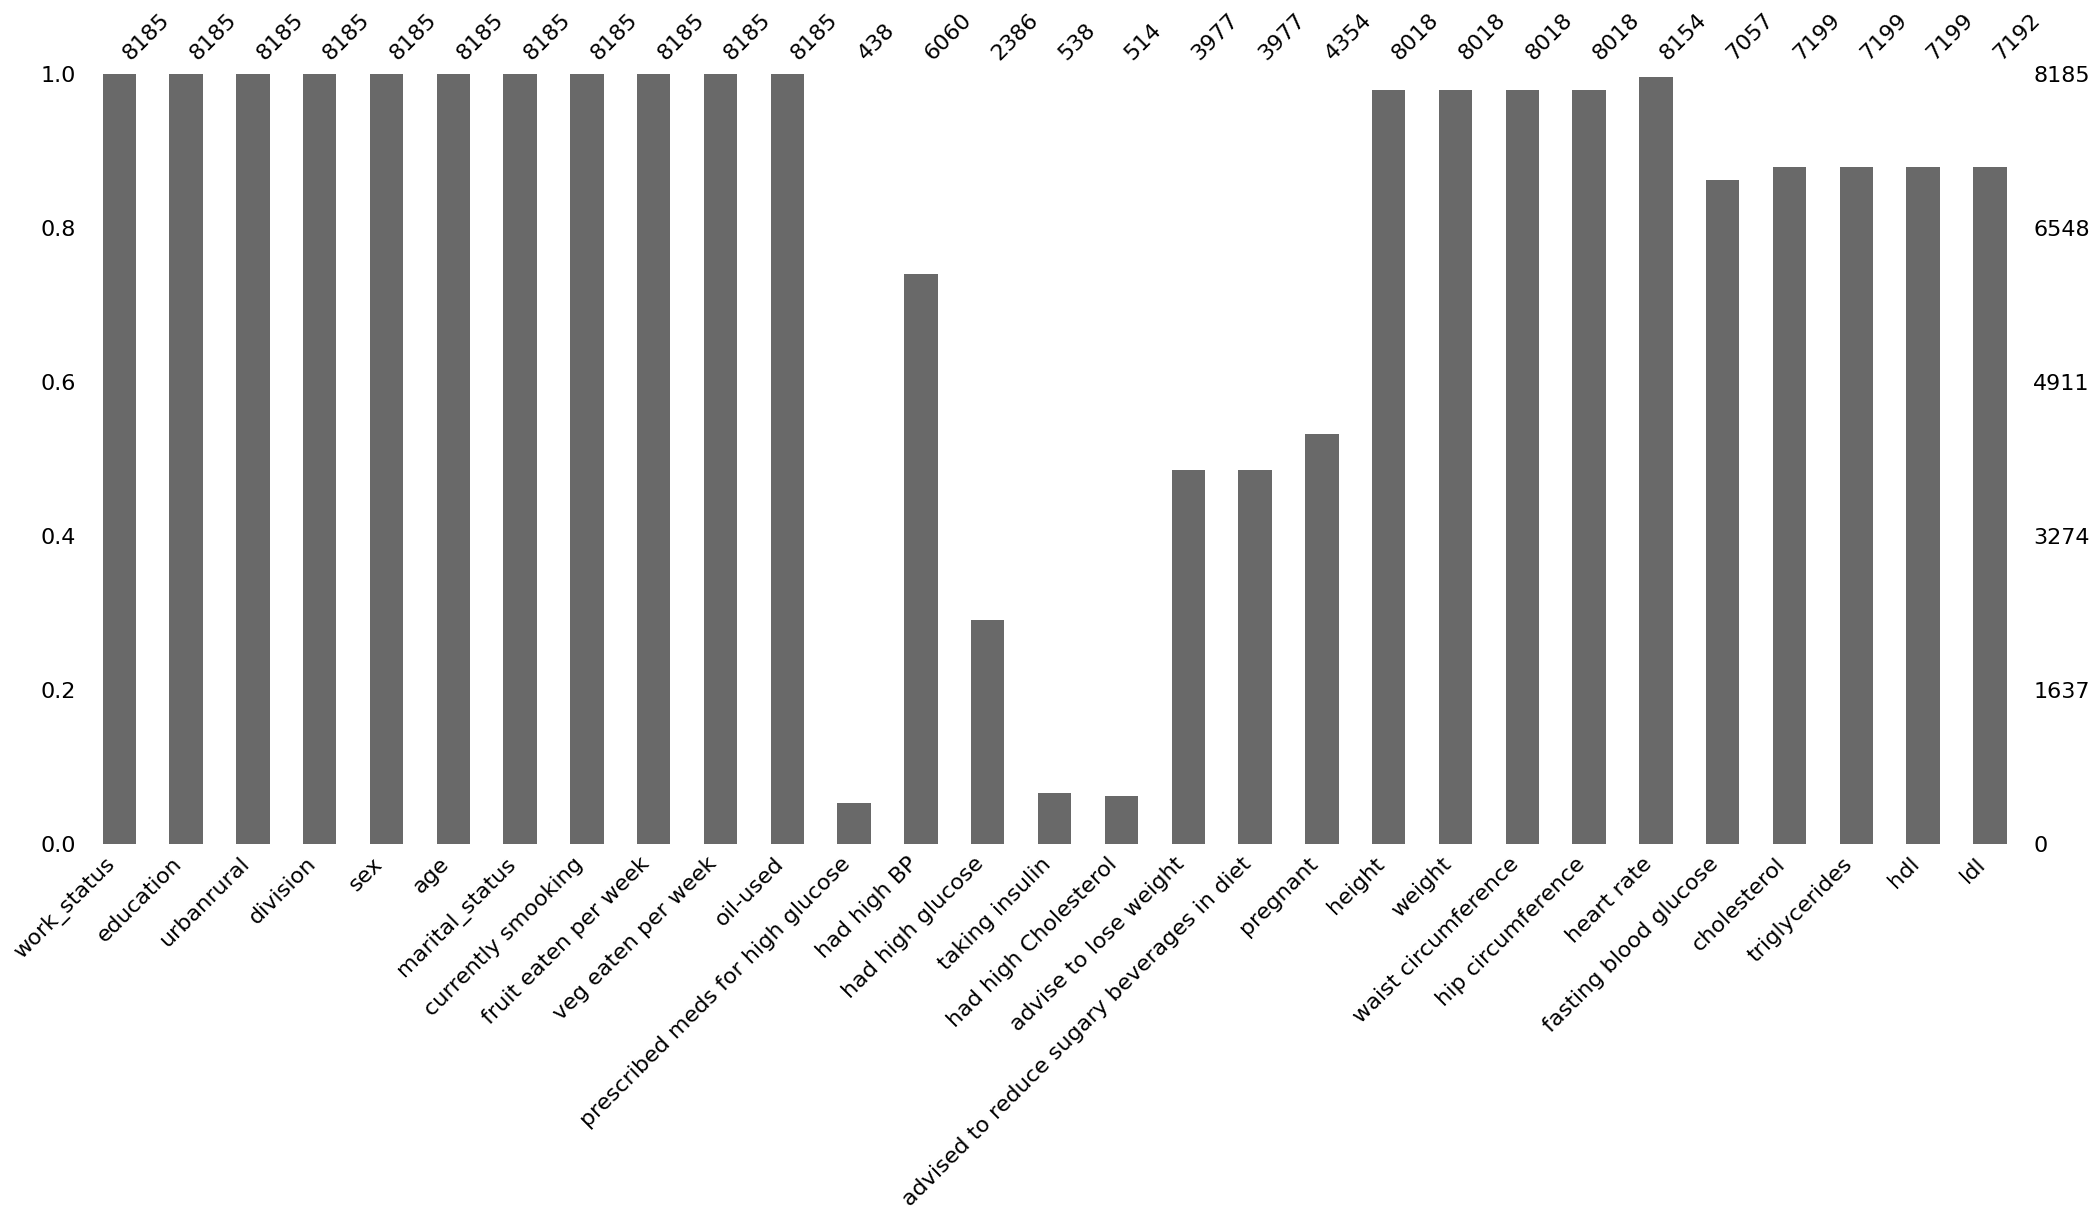

In [ ]:
msno.bar(df_ncd)
plt.show()

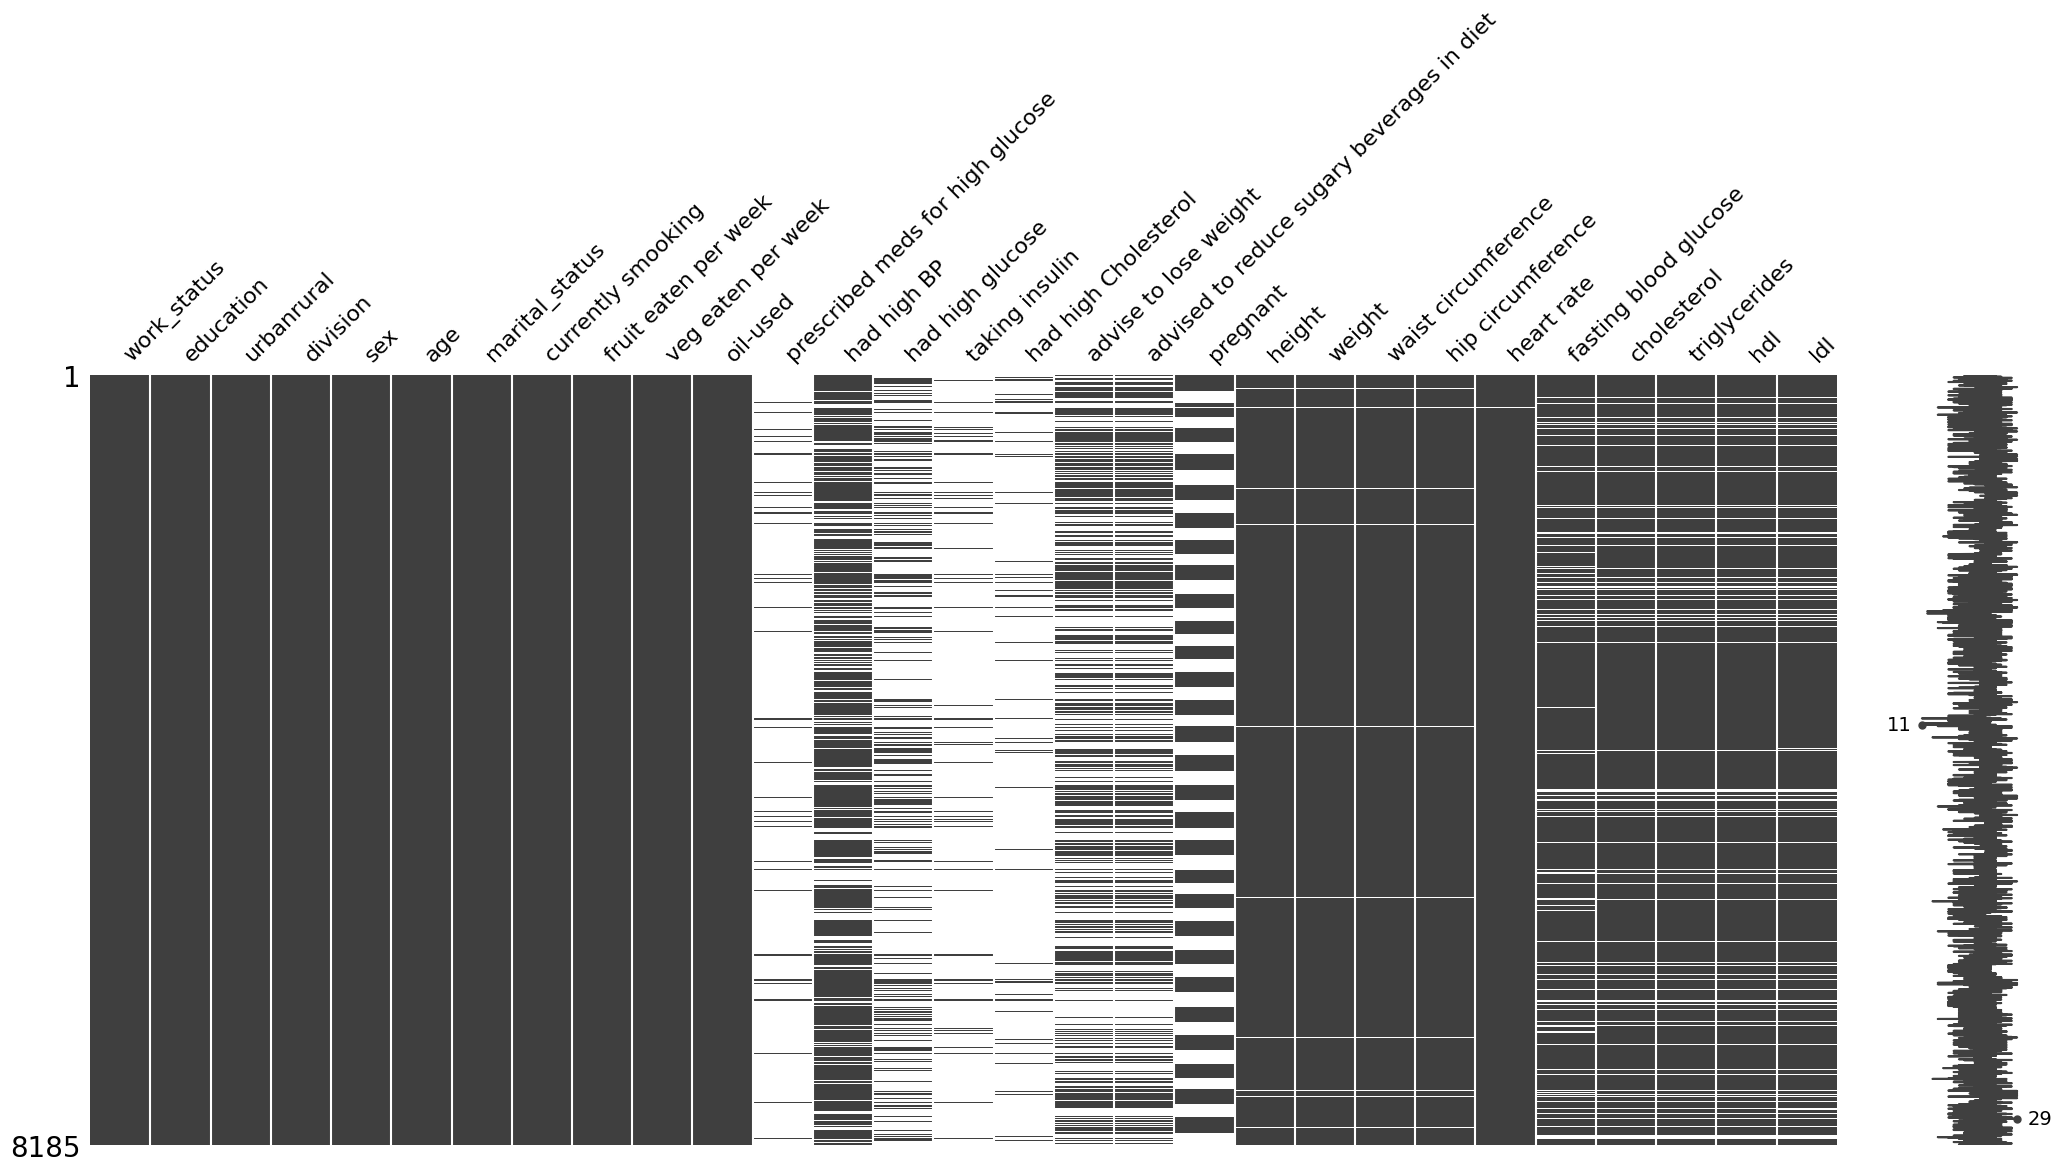

In [ ]:
msno.matrix(df_ncd)
plt.show()

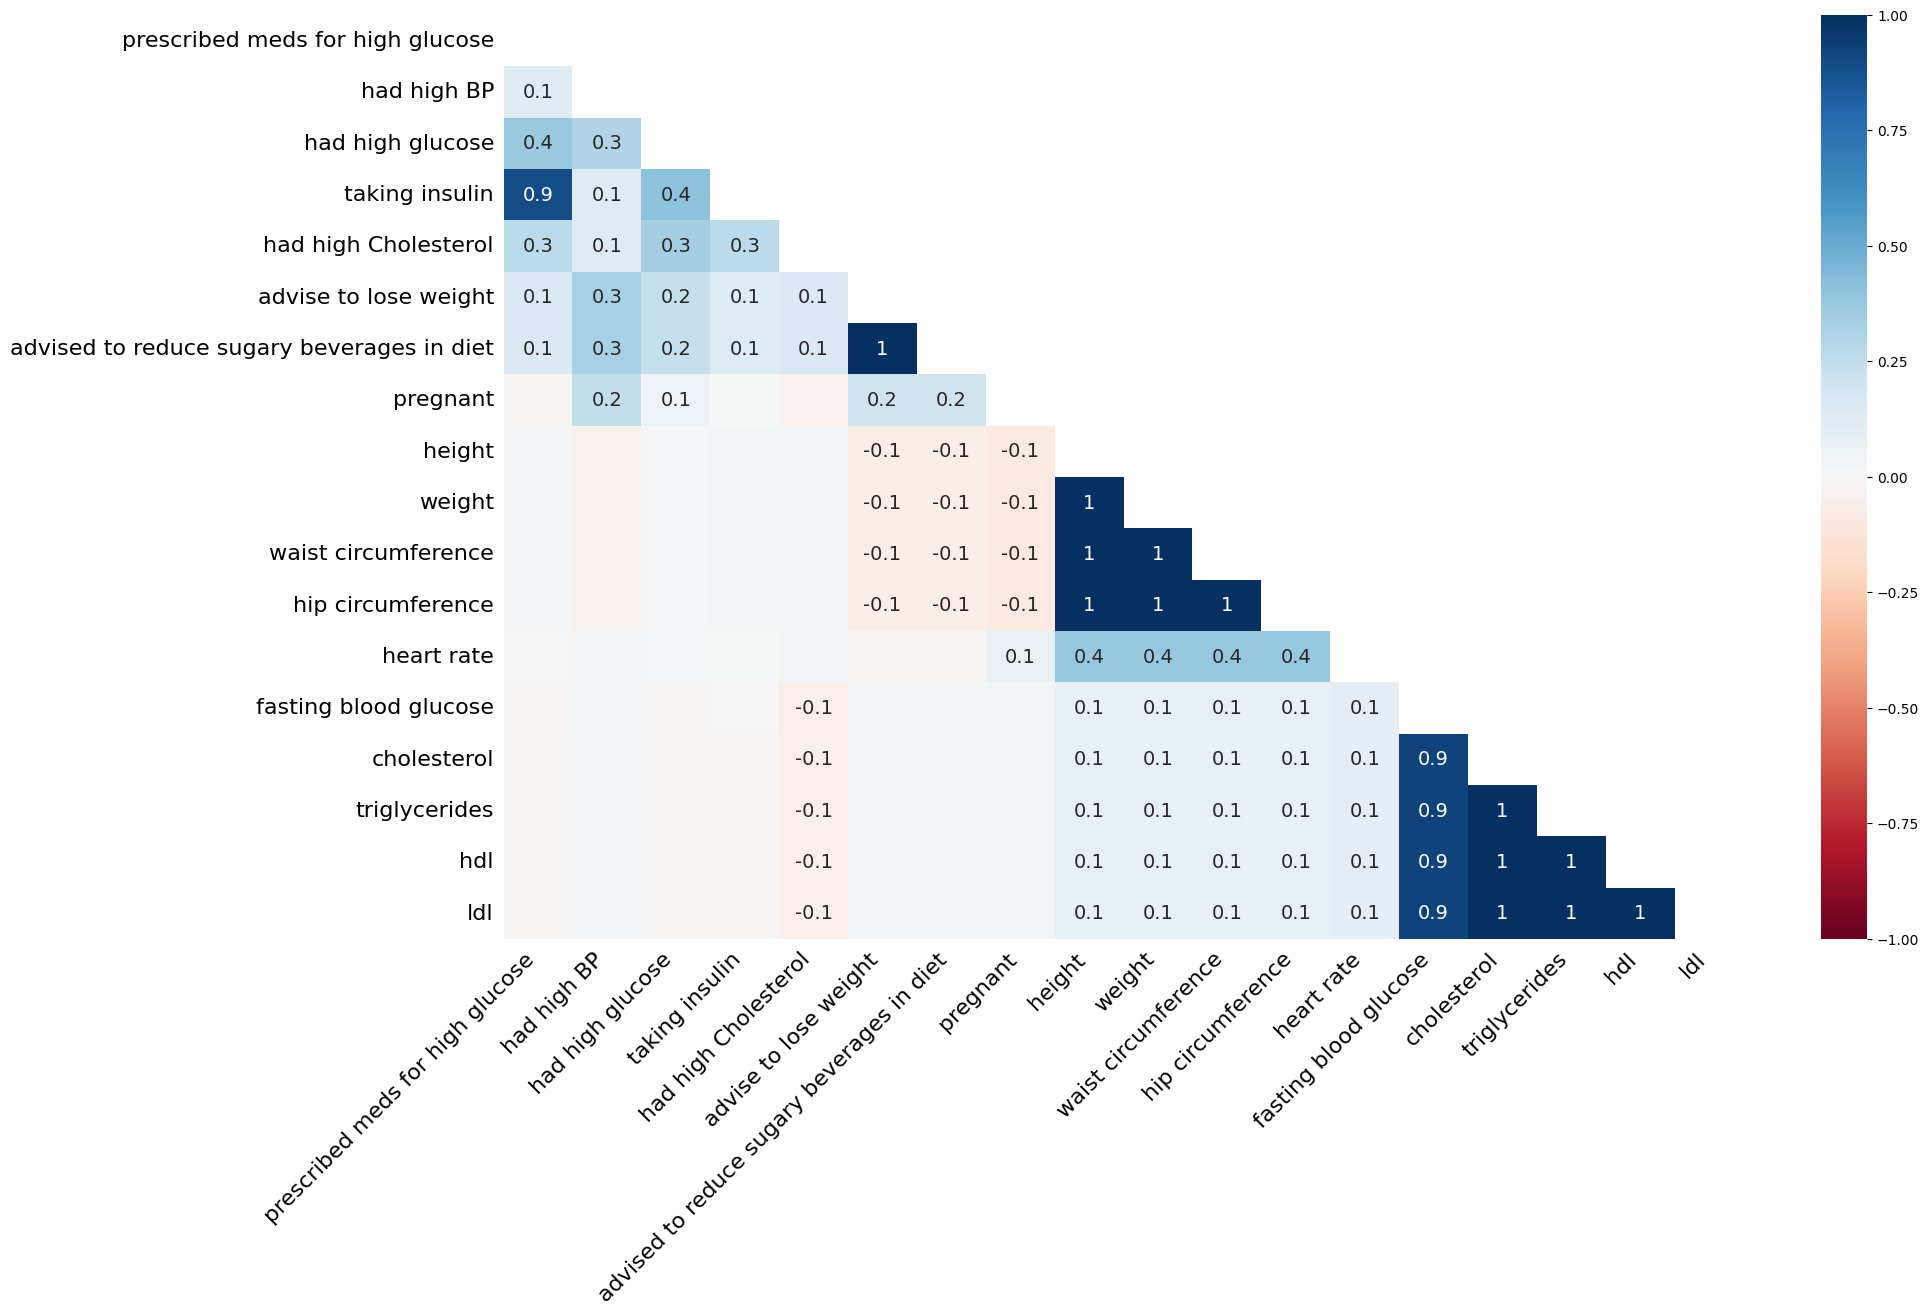

In [ ]:
msno.heatmap(df_ncd)
plt.show()

In [ ]:
# Calculate the min and max for each column
min_values = df_ncd.min()
max_values = df_ncd.max()

# Combine min and max into a single DataFrame for better visualization
min_max_summary = pd.DataFrame({'Min': min_values, 'Max': max_values})

# Display the result
print(min_max_summary)

                                                Min      Max
work_status                                       1       88
education                                         1       88
urbanrural                                    Rural    Urban
division                                          1        8
sex                                               0        1
age                                              18       69
marital_status                                    1        5
currently smooking                                1        2
fruit eaten per week                              0       77
veg eaten per week                                0       77
oil-used                                          1        9
prescribed meds for high glucose              1.000    2.000
had high BP                                   1.000    2.000
had high glucose                              1.000    2.000
taking insulin                                1.000    2.000
had high Cholesterol    

In [ ]:
# List of features to analyze
binary_features = ['taking insulin', 'had high BP', 'had high Cholesterol', 'had high glucose', 'prescribed meds for high glucose', 'advise to lose weight', 'advised to reduce sugary beverages in diet', 'pregnant']

# Function to calculate the percentage of each value (1 and 2) in the columns
def calculate_percentage(df_ncd, columns):
    for column in columns:
        if column in df_ncd.columns:
            value_counts = df_ncd[column].value_counts(normalize=True) * 100
            print(f"Percentages for '{column}':")
            for value, percentage in value_counts.items():
                print(f"  Value {value}: {percentage:.2f}%")
            print("-" * 40)
        else:
            print(f"Column '{column}' not found in the dataset.")
            print("-" * 40)

# Call the function
calculate_percentage(df_ncd, binary_features)

Percentages for 'taking insulin':
  Value 2.0: 79.74%
  Value 1.0: 20.26%
----------------------------------------
Percentages for 'had high BP':
  Value 2.0: 76.75%
  Value 1.0: 23.25%
----------------------------------------
Percentages for 'had high Cholesterol':
  Value 2.0: 51.36%
  Value 1.0: 48.64%
----------------------------------------
Percentages for 'had high glucose':
  Value 2.0: 77.45%
  Value 1.0: 22.55%
----------------------------------------
Percentages for 'prescribed meds for high glucose':
  Value 1.0: 80.59%
  Value 2.0: 19.41%
----------------------------------------
Percentages for 'advise to lose weight':
  Value 2.0: 80.09%
  Value 1.0: 19.91%
----------------------------------------
Percentages for 'advised to reduce sugary beverages in diet':
  Value 2.0: 81.95%
  Value 1.0: 18.05%
----------------------------------------
Percentages for 'pregnant':
  Value 2.0: 96.81%
  Value 1.0: 3.19%
----------------------------------------


In [ ]:
# List of binary features
binary_features = ['taking insulin', 'had high BP', 'had high Cholesterol', 'had high glucose', 'prescribed meds for high glucose', 'advise to lose weight', 'advised to reduce sugary beverages in diet', 'pregnant']

# Replace missing values in binary features with the most frequent value
for col in binary_features:
    if col in df_ncd.columns:
        most_frequent = df_ncd[col].mode()[0]  # Get the most frequent value
        df_ncd[col].fillna(most_frequent, inplace=True)  # Replace missing values
    else:
        print(f"Column '{col}' not found in the dataset.")

# Verify if missing values have been filled
print(df_ncd[binary_features].isnull().sum())

taking insulin                                0
had high BP                                   0
had high Cholesterol                          0
had high glucose                              0
prescribed meds for high glucose              0
advise to lose weight                         0
advised to reduce sugary beverages in diet    0
pregnant                                      0
dtype: int64


In [ ]:
# List of features to analyze
binary_features = ['taking insulin', 'had high BP', 'had high Cholesterol', 'had high glucose', 'prescribed meds for high glucose', 'advise to lose weight', 'advised to reduce sugary beverages in diet', 'pregnant']

# Function to calculate the percentage of each value (1 and 2) in the columns
def calculate_percentage(df_ncd, columns):
    for column in columns:
        if column in df_ncd.columns:
            value_counts = df_ncd[column].value_counts(normalize=True) * 100
            print(f"Percentages for '{column}':")
            for value, percentage in value_counts.items():
                print(f"  Value {value}: {percentage:.2f}%")
            print("-" * 40)
        else:
            print(f"Column '{column}' not found in the dataset.")
            print("-" * 40)

# Call the function
calculate_percentage(df_ncd, binary_features)

Percentages for 'taking insulin':
  Value 2.0: 98.67%
  Value 1.0: 1.33%
----------------------------------------
Percentages for 'had high BP':
  Value 2.0: 82.79%
  Value 1.0: 17.21%
----------------------------------------
Percentages for 'had high Cholesterol':
  Value 2.0: 96.95%
  Value 1.0: 3.05%
----------------------------------------
Percentages for 'had high glucose':
  Value 2.0: 93.43%
  Value 1.0: 6.57%
----------------------------------------
Percentages for 'prescribed meds for high glucose':
  Value 1.0: 98.96%
  Value 2.0: 1.04%
----------------------------------------
Percentages for 'advise to lose weight':
  Value 2.0: 90.32%
  Value 1.0: 9.68%
----------------------------------------
Percentages for 'advised to reduce sugary beverages in diet':
  Value 2.0: 91.23%
  Value 1.0: 8.77%
----------------------------------------
Percentages for 'pregnant':
  Value 2.0: 98.30%
  Value 1.0: 1.70%
----------------------------------------


In [ ]:
# List of columns to replace missing values with the mean
columns_to_fill_mean = ['triglycerides', 'height', 'weight', 'heart rate',
                        'cholesterol', 'waist circumference', 'hip circumference',
                        'fasting blood glucose', 'hdl', 'ldl']

# Replace missing values with the mean for each specified column
for column in columns_to_fill_mean:
    df_ncd[column] = df_ncd[column].fillna(df_ncd[column].mean())

# Verify by checking if there are still any missing values in these columns
print(df_ncd[columns_to_fill_mean].isnull().sum())  # Should return 0 for all

triglycerides            0
height                   0
weight                   0
heart rate               0
cholesterol              0
waist circumference      0
hip circumference        0
fasting blood glucose    0
hdl                      0
ldl                      0
dtype: int64


In [ ]:
# Define the ranges for each column
cholesterol_range = (0, 500)
hdl_range = (0, 300)
ldl_range = (0, 300)

# Filter the DataFrame to keep only rows within the specified ranges
filtered_df = df_ncd[
    (df_ncd['cholesterol'].between(*cholesterol_range)) &
    (df_ncd['hdl'].between(*hdl_range)) &
    (df_ncd['ldl'].between(*ldl_range))
]

# modify the original DataFrame in place
df_ncd = filtered_df

# Display the filtered DataFrame
print(df_ncd)


      work_status  education urbanrural  division  sex  age  marital_status  \
0              12          1      Urban         1    0   22               2   
1               1          5      Urban         1    0   50               2   
2              12          1      Rural         1    0   39               2   
3              12          1      Rural         1    0   29               2   
4              12          3      Rural         1    0   32               2   
...           ...        ...        ...       ...  ...  ...             ...   
8180            2          6      Urban         8    1   53               2   
8181           15          5      Urban         8    1   63               2   
8182           13          7      Urban         8    1   50               2   
8183            1          5      Urban         8    1   40               2   
8184            3          1      Urban         8    1   47               2   

      currently smooking  fruit eaten per week  veg

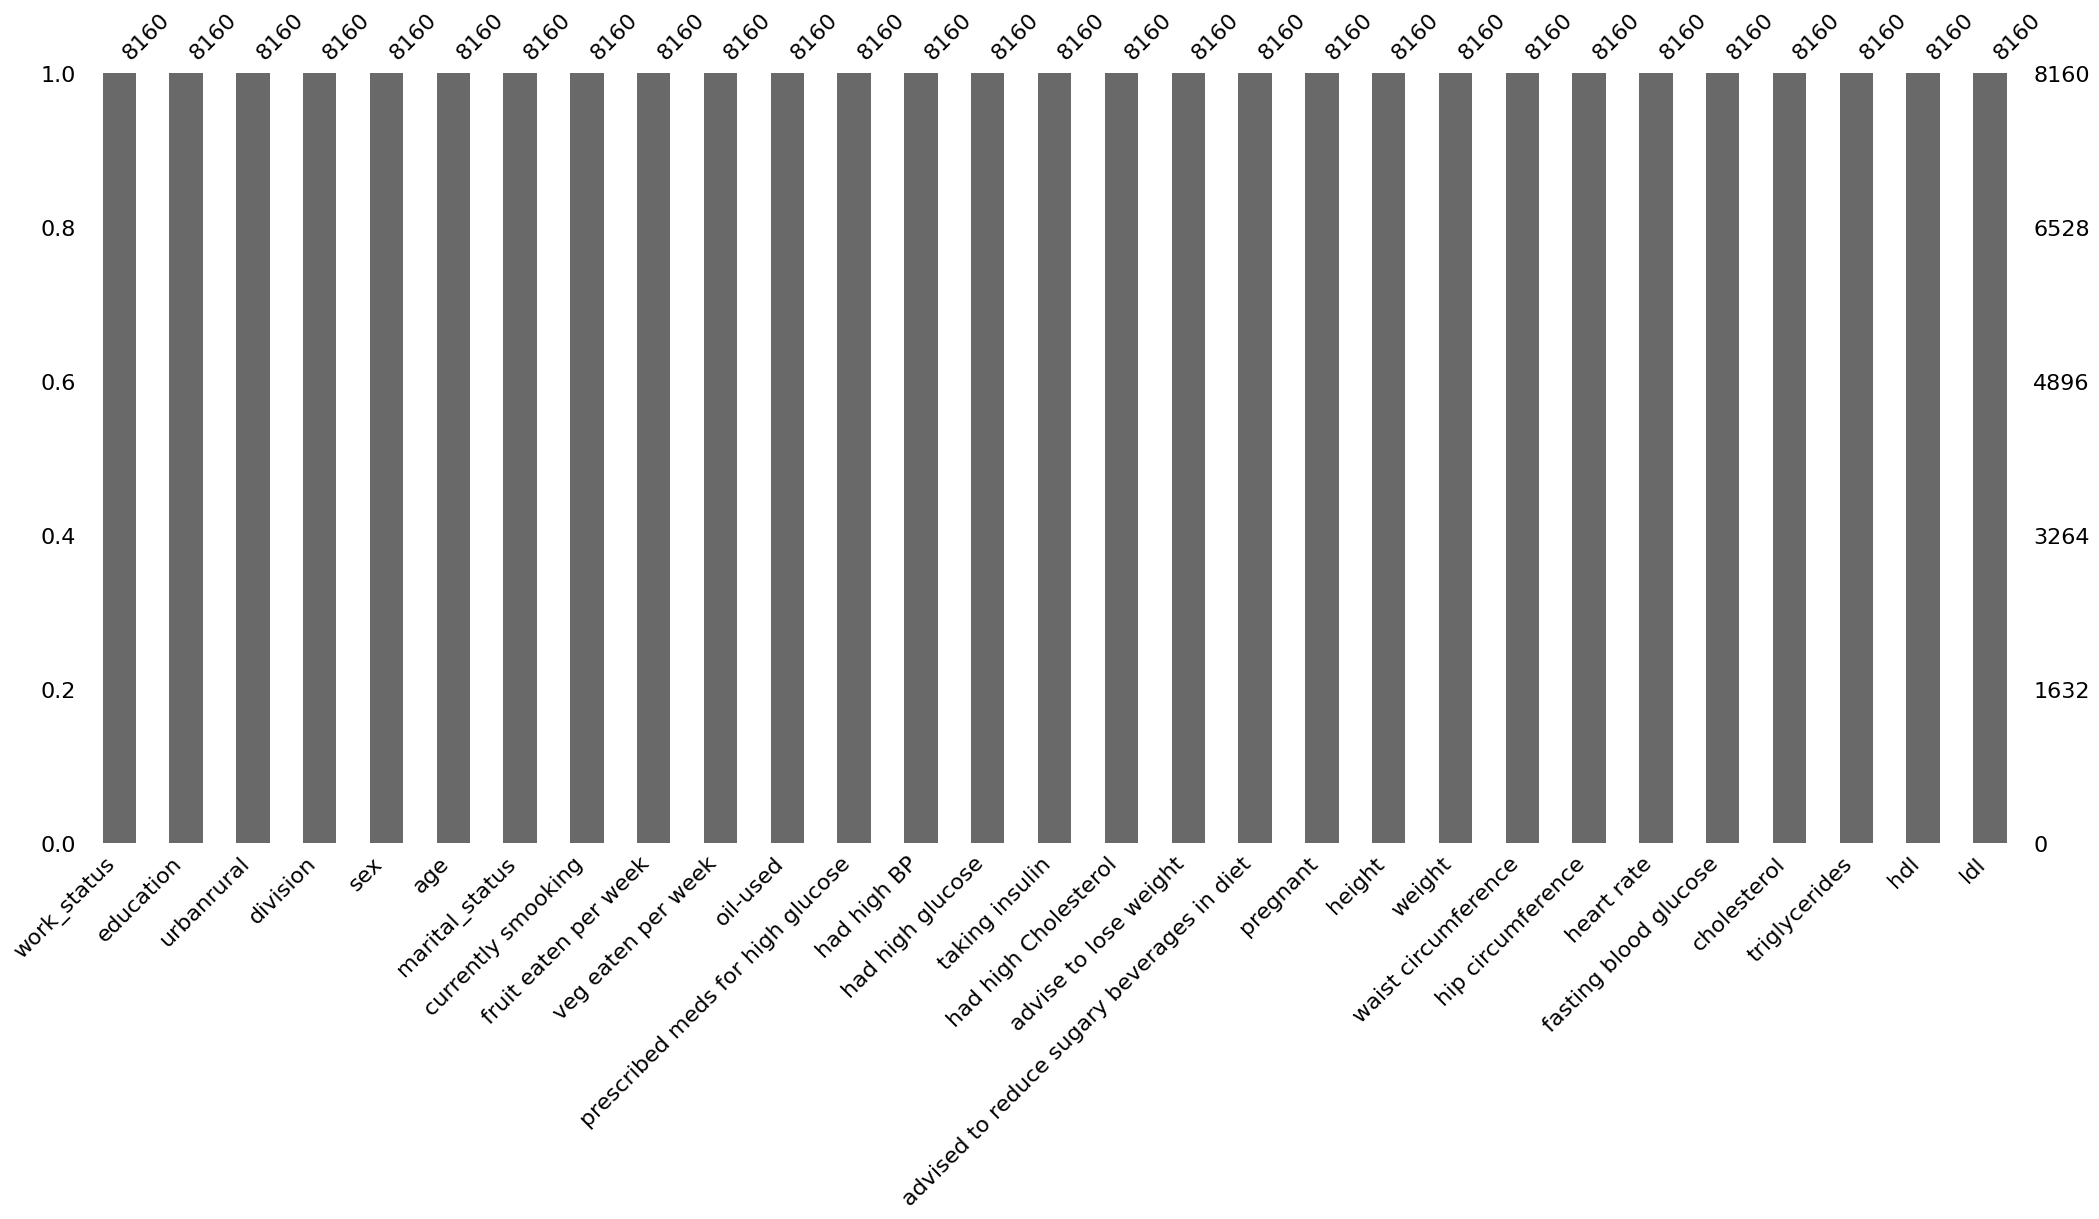

In [ ]:
msno.bar(df_ncd)
plt.show()

In [ ]:
(df_ncd.isnull().sum())*100/len(df_ncd)

,0
work_status,0.000
education,0.000
urbanrural,0.000
division,0.000
sex,0.000
age,0.000
marital_status,0.000
currently smooking,0.000
fruit eaten per week,0.000
veg eaten per week,0.000


In [ ]:
df_ncd.duplicated().sum()

0

In [ ]:
pip install pandas seaborn matplotlib

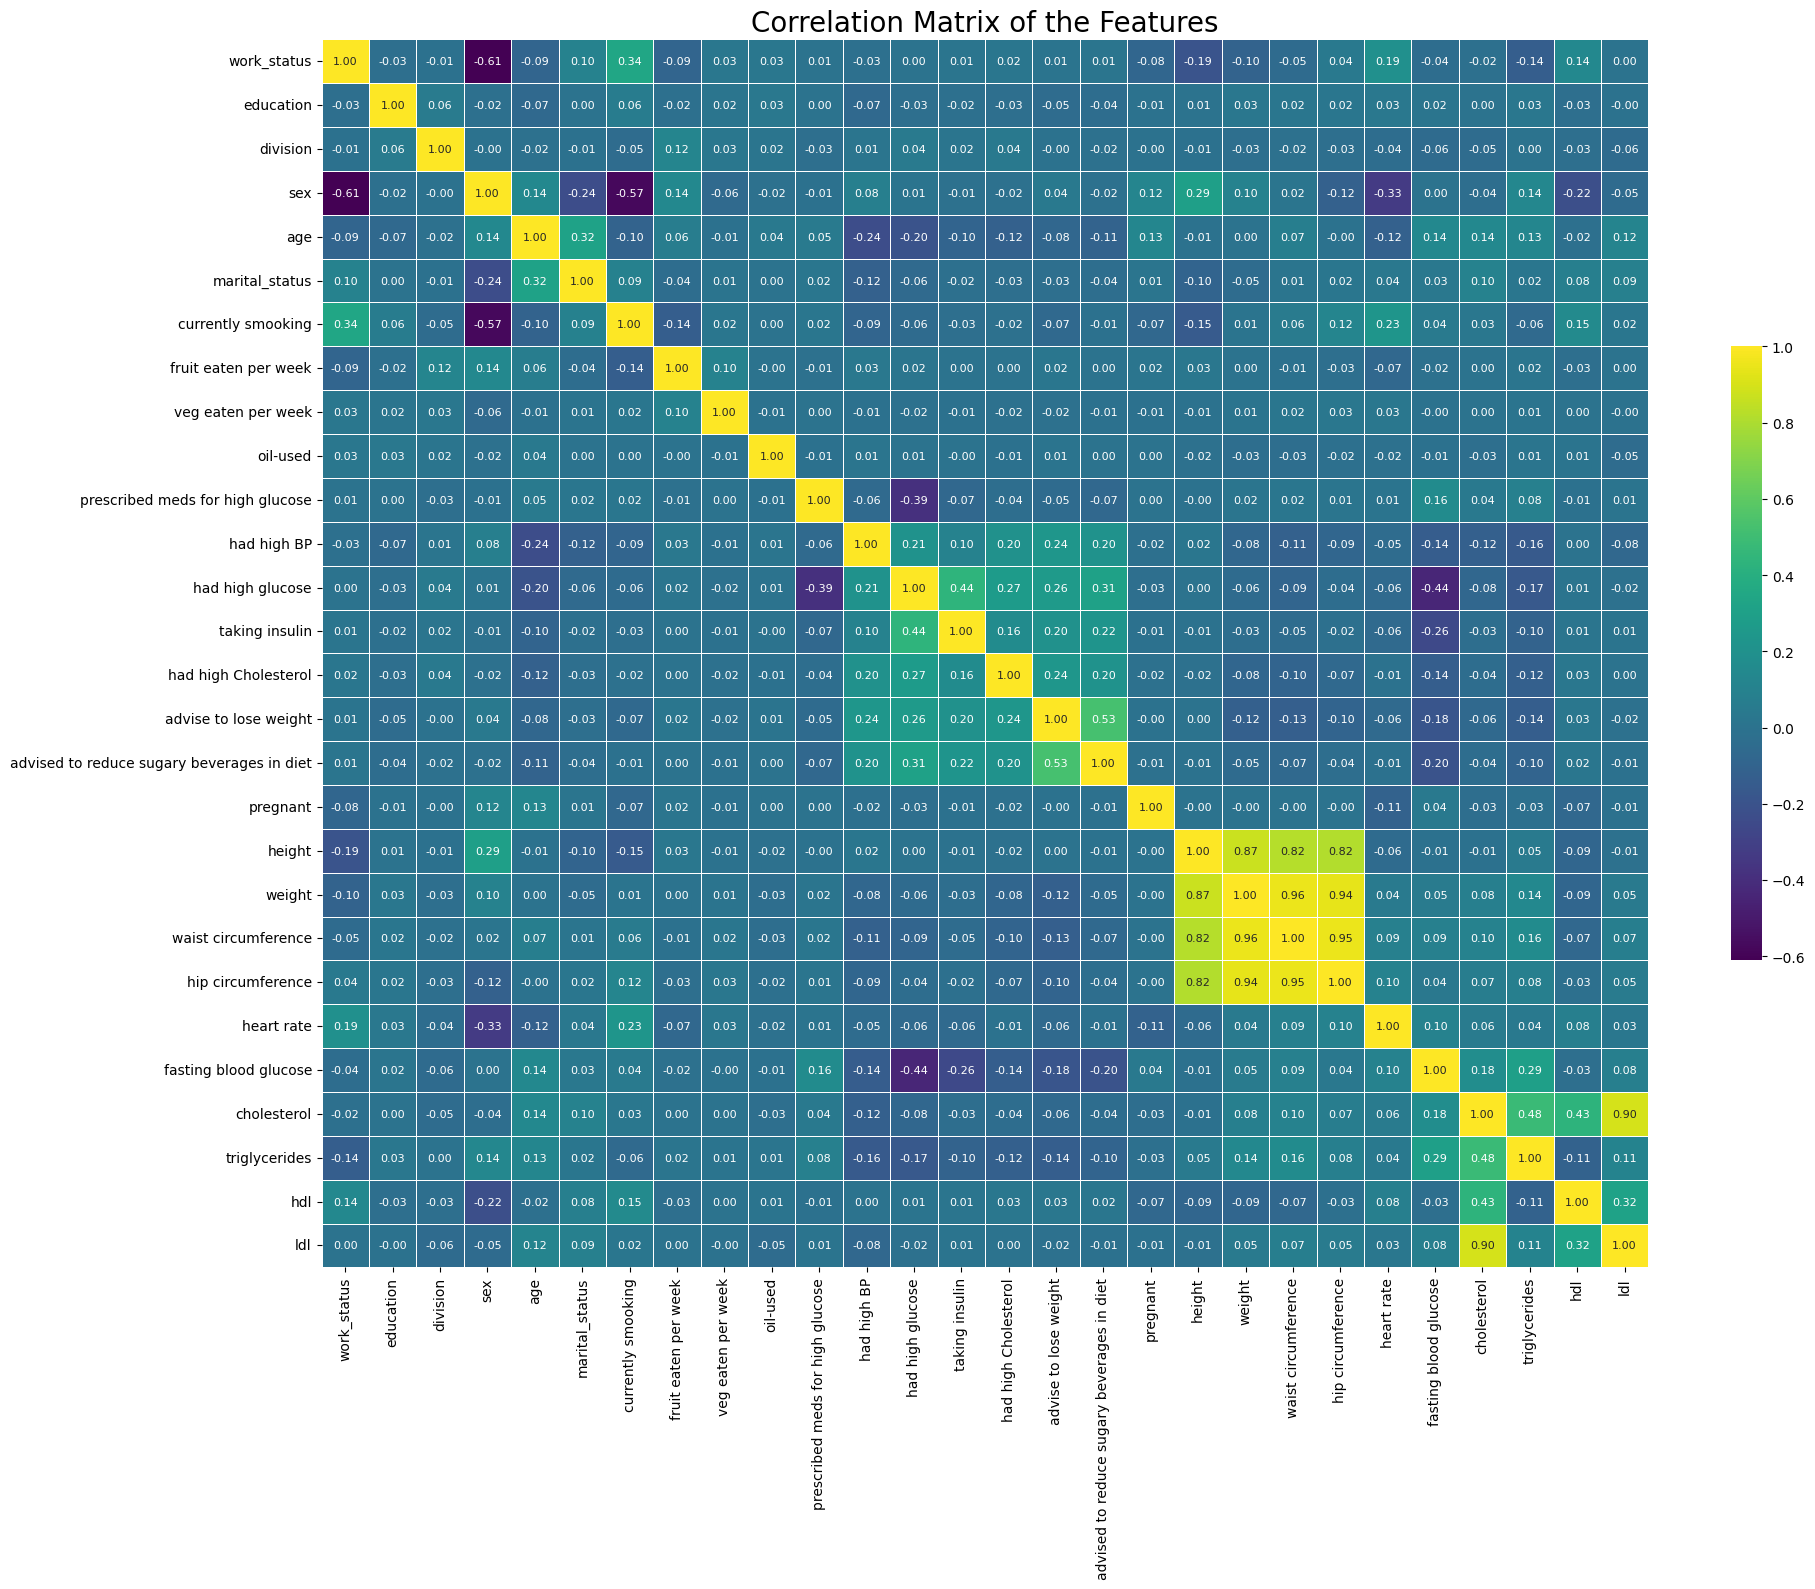

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the correlation matrix
df = df_ncd
# Select only numerical columns for correlation calculation
numerical_df = df.select_dtypes(include=['number'])
correlation_matrix = numerical_df.corr()

# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(20, 16))
heatmap = sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='viridis', linewidths=0.5, cbar_kws={'shrink': .5}, annot_kws={"size": 8})
plt.title('Correlation Matrix of the Features', fontsize=20)
plt.xticks(rotation=90, fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()  # Adjust layout to ensure everything fits without overlap
plt.show()

In [ ]:
df_ncd.shape

(8160, 29)

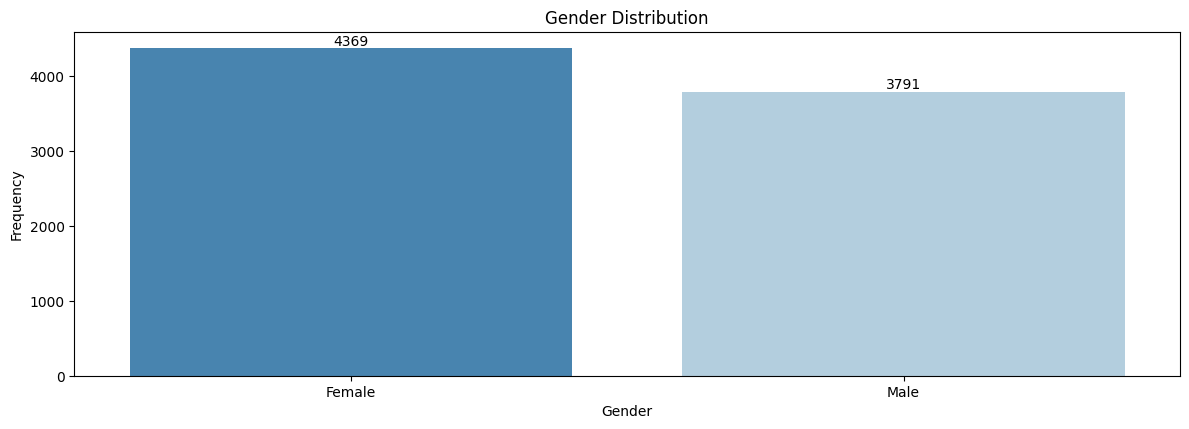

In [ ]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_ncd['sex'] = df_ncd['sex'].replace({0: 'Female', 1: 'Male'})

# Function to annotate bars with counts
def annotate_barplot(ax):
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black')

# Plotting the bar charts similar to the image layout
plt.figure(figsize=(12, 12))

# 1. Gender distribution
plt.subplot(3, 1, 1)
ax1 = sns.countplot(x='sex', data=df_ncd, palette='Blues_r')
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Frequency')
annotate_barplot(ax1)

# Adjust layout for better presentation
plt.tight_layout()
plt.show()


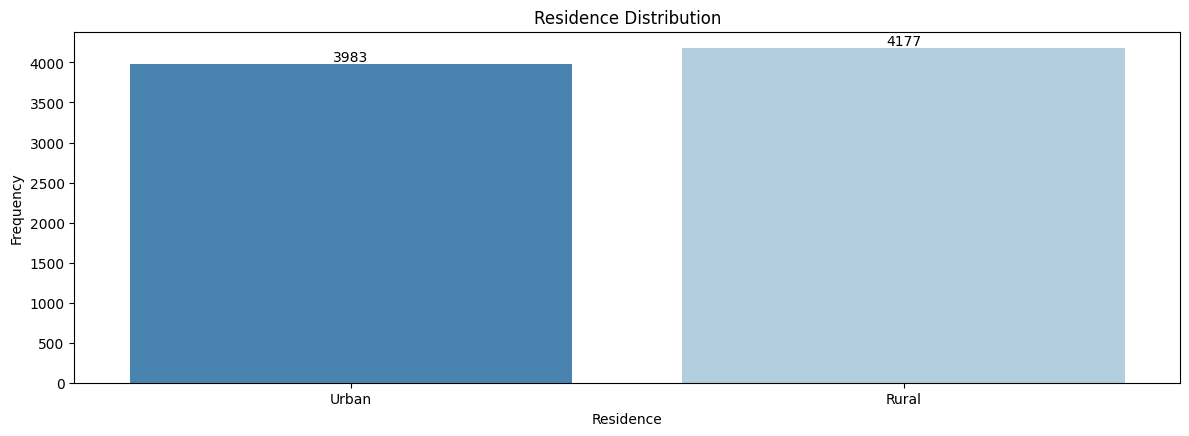

In [ ]:

# Function to annotate bars with counts
def annotate_barplot(ax):
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black')

# Plotting the bar charts similar to the image layout
plt.figure(figsize=(12, 12))

# Urban vs Rural distribution
plt.subplot(3, 1, 2)
ax2 = sns.countplot(x='urbanrural', data=df_ncd, palette='Blues_r')
plt.title('Residence Distribution')
plt.xlabel('Residence')
plt.ylabel('Frequency')
annotate_barplot(ax2)

# Adjust layout for better presentation
plt.tight_layout()
plt.show()

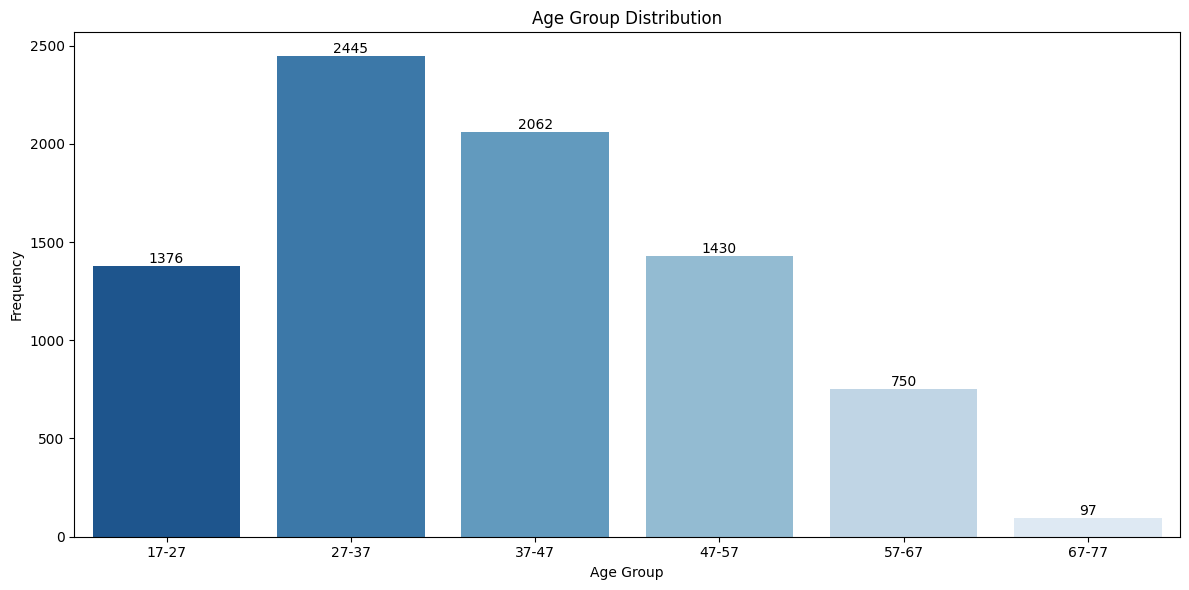

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create age bins (17-27, 27-37, etc.) and add a new 'age_group' column
age_bins = [17, 27, 37, 47, 57, 67, 77]
age_labels = ['17-27', '27-37', '37-47', '47-57', '57-67', '67-77']
df_ncd['age_group'] = pd.cut(df_ncd['age'], bins=age_bins, labels=age_labels, right=False)

# Function to annotate bars with counts
def annotate_barplot(ax):
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black')

# Plotting the bar chart for age group distribution
plt.figure(figsize=(12, 6))

# Age group distribution
ax = sns.countplot(x='age_group', data=df_ncd, palette='Blues_r')
plt.title('Age Group Distribution')
plt.xlabel('Age Group')
plt.ylabel('Frequency')
annotate_barplot(ax)

# Adjust layout for better presentation
plt.tight_layout()
plt.show()


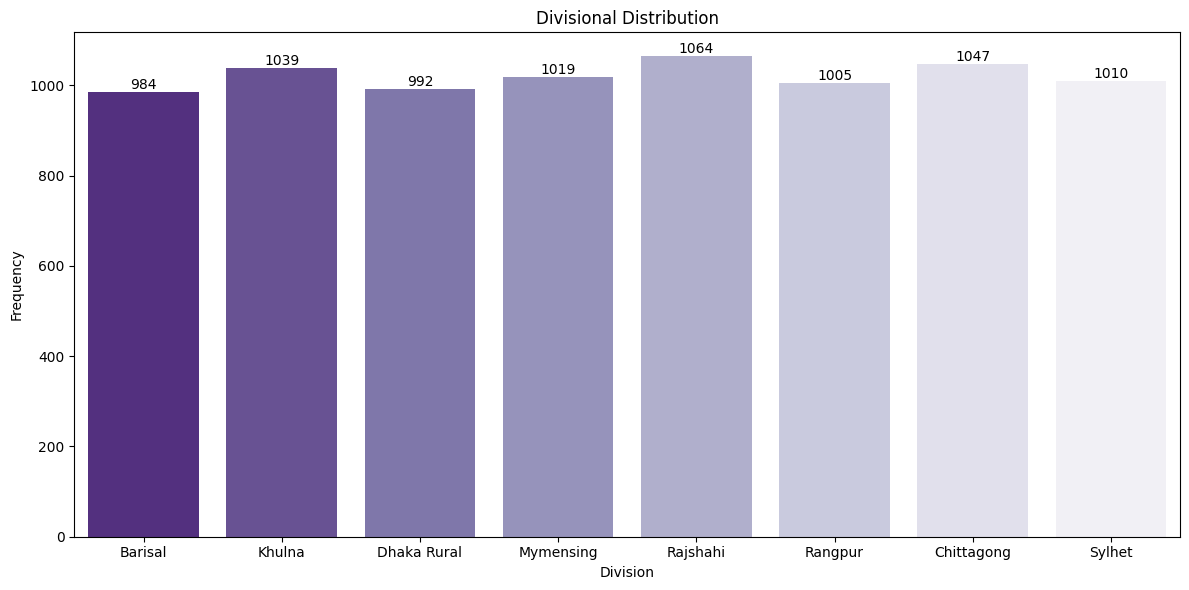

In [ ]:
# Create a dictionary for division mapping
division_mapping = {
    1: 'Barisal',
    2: 'Chittagong',
    3: 'Dhaka Rural',
    4: 'Khulna',
    5: 'Mymensing',
    6: 'Rajshahi',
    7: 'Rangpur',
    8: 'Sylhet'
}

# Assuming 'division_code' is the column in the dataset representing division
df_ncd['division'] = df_ncd['division'].map(division_mapping)

# Function to annotate bars with counts
def annotate_barplot(ax):
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black')

# Plotting the bar chart for division distribution
plt.figure(figsize=(12, 6))

# Division distribution
ax = sns.countplot(x='division', data=df_ncd, palette='Purples_r')
plt.title('Divisional Distribution')
plt.xlabel('Division')
plt.ylabel('Frequency')
annotate_barplot(ax)

# Adjust layout for better presentation
plt.tight_layout()
plt.show()


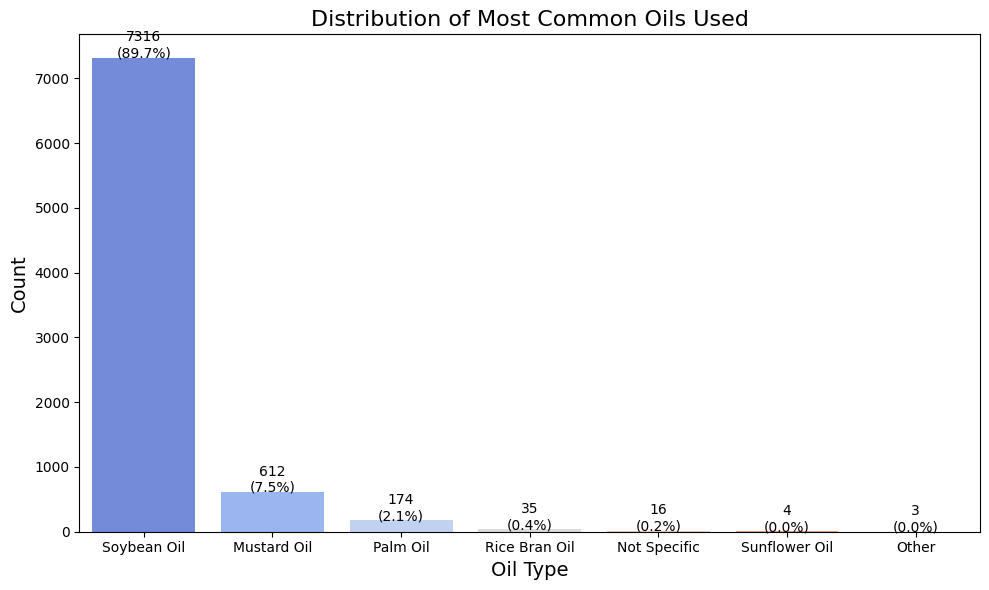

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

oil_mapping = {
    1: 'Soybean Oil',
    2: 'Palm Oil',
    3: 'Sunflower Oil',
    4: 'Mustard Oil',
    5: 'Rice Bran Oil',
    6: 'Dalda',
    7: 'Ghee/Butter',
    8: 'Not Specific',
    9: 'Other'
}

# Map the 'oil-used' column to oil categories
df_ncd['oil_used'] = df_ncd['oil-used'].map(oil_mapping)

# Count the occurrences of each category
oil_counts = df_ncd['oil_used'].value_counts()

# Plot the distribution using a bar plot
plt.figure(figsize=(10, 6))
sns.barplot(x=oil_counts.index, y=oil_counts.values, palette='coolwarm')
plt.title('Distribution of Most Common Oils Used', fontsize=16)
plt.xlabel('Oil Type', fontsize=14)
plt.ylabel('Count', fontsize=14)

# Add the count and percentage on top of each bar
total = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()


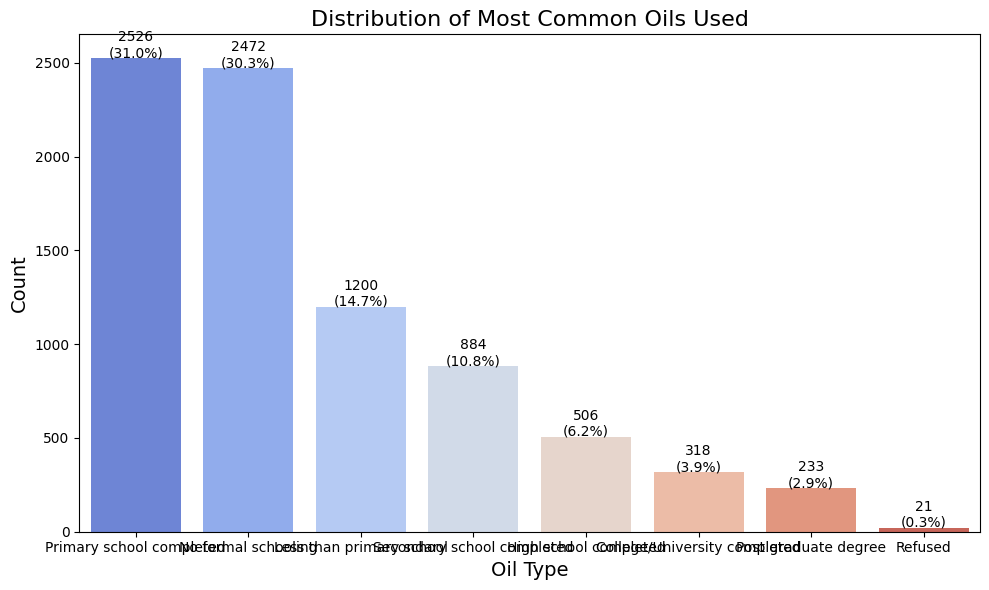

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

oil_mapping = {
    1: 'No formal schooling',
    2: 'Less than primary school',
    3: 'Primary school completed',
    4: 'Secondary school completed',
    5: 'High school completed',
    6: 'College/University completed',
    7: 'Post graduate degree',
    88: 'Refused',

}

# Map the 'oil-used' column to oil categories
df_ncd['education'] = df_ncd['education'].map(oil_mapping)

# Count the occurrences of each category
oil_counts = df_ncd['education'].value_counts()

# Plot the distribution using a bar plot
plt.figure(figsize=(10, 6))
sns.barplot(x=oil_counts.index, y=oil_counts.values, palette='coolwarm')
plt.title('Distribution of Most Common Oils Used', fontsize=16)
plt.xlabel('Oil Type', fontsize=14)
plt.ylabel('Count', fontsize=14)

# Add the count and percentage on top of each bar
total = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()


In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Define the features and safe ranges
features = [
    'had high Cholesterol', 'had high glucose', 'prescribed meds for high glucose',
    'taking insulin', 'advise to lose weight', 'advised to reduce sugary beverages in diet',
    'triglycerides', 'height', 'weight', 'waist circumference', 'hip circumference',
    'cholesterol', 'fasting blood glucose', 'hdl', 'ldl'
]

# Safe ranges for continuous features
safe_ranges = {
    'fasting blood glucose': (70, 99),
    'cholesterol': (0, 200),
    'hdl': (20, 100),
    'ldl': (0, 100),
    'BMI': (18.5, 24.9),  # Healthy BMI range
    'waist-to-hip ratio': (0, 0.9)  # General threshold for lower risk
}

# Calculate derived metrics: BMI and waist-to-hip ratio
def calculate_derived_metrics(row):
    row['BMI'] = row['weight'] / ((row['height'] / 100) ** 2)  # Height converted to meters
    if row['hip circumference'] > 0:  # Avoid division by zero
        row['waist-to-hip ratio'] = row['waist circumference'] / row['hip circumference']
    else:
        row['waist-to-hip ratio'] = 0  # Assign 0 if hip circumference is missing
    return row

# Apply the derived metric calculations to the dataset
df_ncd = df_ncd.apply(calculate_derived_metrics, axis=1)

# Add derived metrics to the features list
features += ['BMI', 'waist-to-hip ratio']

# Assign risk levels based on how far values are from safe ranges
def calculate_risk(row):
    risk = 0
    for feature, (low, high) in safe_ranges.items():
        if feature in row:
            if low <= row[feature] <= high:
                risk += 0  # Low risk, within range
            else:
                risk += 1  # Increment risk for out-of-range values
    return risk

# Apply risk calculation to the dataset
df_ncd['risk_score'] = df_ncd.apply(calculate_risk, axis=1)

# Binary feature adjustments: Map binary values to reflect risk directly
binary_features = [
    'had high Cholesterol', 'had high glucose', 'prescribed meds for high glucose',
    'advise to lose weight', 'taking insulin', 'advised to reduce sugary beverages in diet'
]

# Map binary values: 1 for high risk, -1 for protective (if applicable), 0 for neutral
df_ncd[binary_features] = df_ncd[binary_features].replace({2: -1, 1: 1, 0: 0})

# Combine risk scores with binary features for clustering
selected_features = list(safe_ranges.keys()) + binary_features + ['risk_score']

# Scale features for clustering
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_ncd[selected_features])

# Apply K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42)
df_ncd['Risk of Diabetes'] = kmeans.fit_predict(df_scaled)

# Map the clusters to risk categories
cluster_centers = kmeans.cluster_centers_
cluster_risk_scores = cluster_centers[:, selected_features.index('risk_score')]
risk_mapping = dict(zip(np.argsort(cluster_risk_scores), ['Low', 'Medium', 'High']))
df_ncd['Risk of Diabetes'] = df_ncd['Risk of Diabetes'].map(risk_mapping)

# Output the results
print("Clustering complete. Here is the distribution of risk categories:")
print(df_ncd['Risk of Diabetes'].value_counts())
print("First few rows with risk categories:")
print(df_ncd[['Risk of Diabetes'] + selected_features].head())


Clustering complete. Here is the distribution of risk categories:
Risk of Diabetes
Low       4580
Medium    3105
High       475
Name: count, dtype: int64
First few rows with risk categories:
  Risk of Diabetes  fasting blood glucose  cholesterol    hdl     ldl    BMI  \
0              Low                 97.000      179.000 37.000 121.000 19.703   
1           Medium                 99.583      169.257 38.165 101.790 26.266   
2              Low                100.000      168.000 29.000 111.000 21.645   
3              Low                 90.000      134.000 43.000  77.400 22.406   
4           Medium                 99.000      231.000 33.000 151.000 24.762   

   waist-to-hip ratio  had high Cholesterol  had high glucose  \
0               0.739                -1.000            -1.000   
1               0.823                -1.000             1.000   
2               0.783                -1.000            -1.000   
3               0.694                -1.000            -1.000   
4  

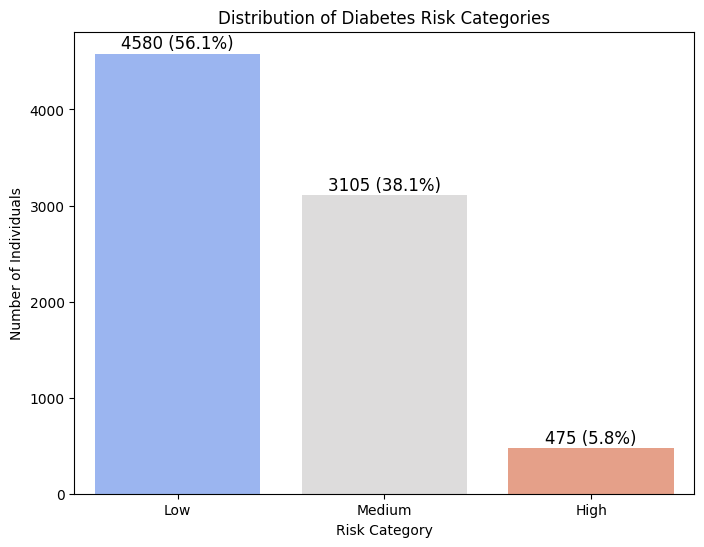

In [ ]:
# Import necessary libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Count the occurrences of each risk category and calculate percentages
risk_counts = df_ncd['Risk of Diabetes'].value_counts()
risk_percentages = (risk_counts / risk_counts.sum()) * 100

# Set up the plot
plt.figure(figsize=(8, 6))
sns.barplot(x=risk_counts.index, y=risk_counts.values, palette="coolwarm")

# Add titles and labels
plt.title("Distribution of Diabetes Risk Categories")
plt.xlabel("Risk Category")
plt.ylabel("Number of Individuals")

# Add percentage and count labels on top of each bar
for i, (count, pct) in enumerate(zip(risk_counts.values, risk_percentages.values)):
    plt.text(i, count + 10, f'{count} ({pct:.1f}%)', ha='center', va='bottom', fontsize=12)

plt.xticks(rotation=0)
plt.show()



In [ ]:
# Separate data into High, Medium, and Low risk categories
high_risk = df_ncd[df_ncd['Risk of Diabetes'] == 'High']
medium_risk = df_ncd[df_ncd['Risk of Diabetes'] == 'Medium']
low_risk = df_ncd[df_ncd['Risk of Diabetes'] == 'Low']

# Calculate descriptive statistics for each risk category
high_risk_stats = high_risk[features].describe()
medium_risk_stats = medium_risk[features].describe()
low_risk_stats = low_risk[features].describe()

# Display the statistics for each risk category
print("High Risk Category Statistics:")
print(high_risk_stats)

print("\nMedium Risk Category Statistics:")
print(medium_risk_stats)

print("\nLow Risk Category Statistics:")
print(low_risk_stats)


High Risk Category Statistics:
       had high Cholesterol  had high glucose  \
count               475.000           475.000   
mean                 -0.394             0.798   
std                   0.920             0.603   
min                  -1.000            -1.000   
25%                  -1.000             1.000   
50%                  -1.000             1.000   
75%                   1.000             1.000   
max                   1.000             1.000   

       prescribed meds for high glucose  taking insulin  \
count                           475.000         475.000   
mean                              0.642          -0.541   
std                               0.767           0.842   
min                              -1.000          -1.000   
25%                               1.000          -1.000   
50%                               1.000          -1.000   
75%                               1.000          -1.000   
max                               1.000           1.000

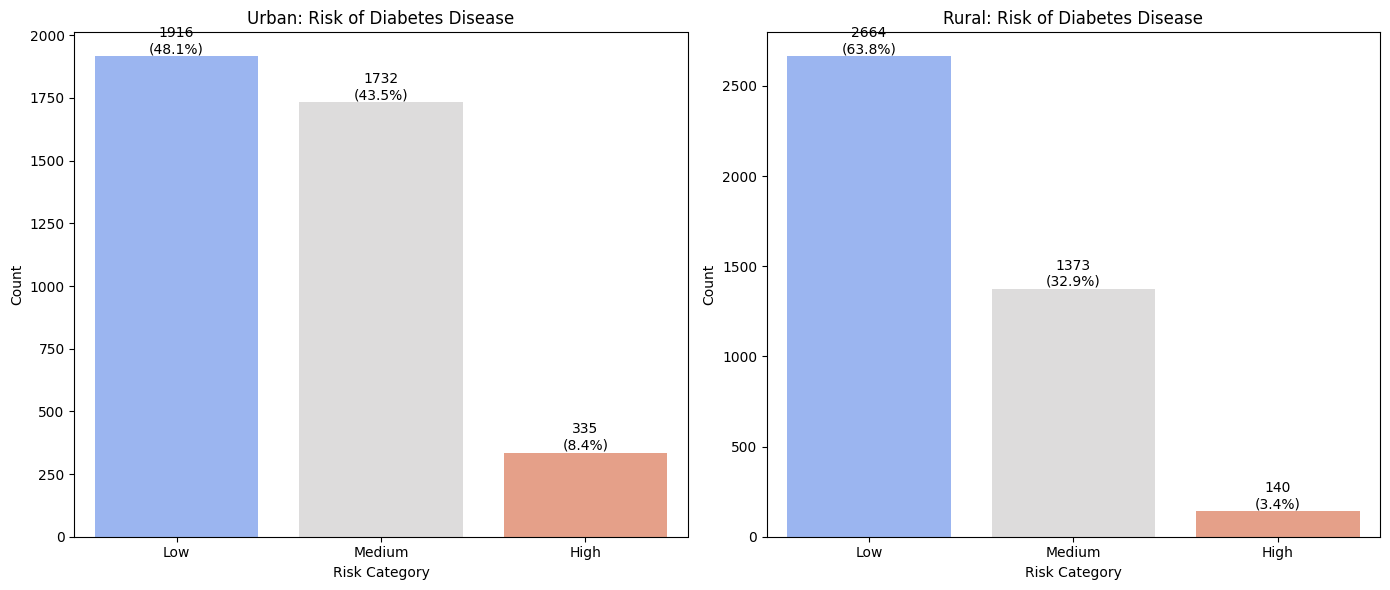

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Separate data for urban and rural categories
urban_data = df_ncd[df_ncd['urbanrural'] == 'Urban']  # or df_ncd['urbanrural'] == 1
rural_data = df_ncd[df_ncd['urbanrural'] == 'Rural']  # or df_ncd['urbanrural'] == 2

# Calculate counts and percentages for each category
urban_counts = urban_data['Risk of Diabetes'].value_counts()
urban_percentages = urban_data['Risk of Diabetes'].value_counts(normalize=True) * 100

rural_counts = rural_data['Risk of Diabetes'].value_counts()
rural_percentages = rural_data['Risk of Diabetes'].value_counts(normalize=True) * 100

# Plotting counts and percentages for each risk category in Urban and Rural
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Urban Risk of Diabetes (Counts and Percentages)
sns.barplot(x=urban_counts.index, y=urban_counts.values, ax=axes[0], palette='coolwarm')
axes[0].set_title('Urban: Risk of Diabetes Disease')
axes[0].set_xlabel('Risk Category')
axes[0].set_ylabel('Count')

# Adding count and percentage labels for Urban data
for i, count in enumerate(urban_counts):
    percentage = urban_percentages[i]
    axes[0].text(i, count + 1, f'{count}\n({percentage:.1f}%)',
                 ha='center', va='bottom', color='black', fontsize=10)

# Rural Risk of Diabetes (Counts and Percentages)
sns.barplot(x=rural_counts.index, y=rural_counts.values, ax=axes[1], palette='coolwarm')
axes[1].set_title('Rural: Risk of Diabetes Disease')
axes[1].set_xlabel('Risk Category')
axes[1].set_ylabel('Count')

# Adding count and percentage labels for Rural data
for i, count in enumerate(rural_counts):
    percentage = rural_percentages[i]
    axes[1].text(i, count + 1, f'{count}\n({percentage:.1f}%)',
                 ha='center', va='bottom', color='black', fontsize=10)

plt.tight_layout()
plt.show()


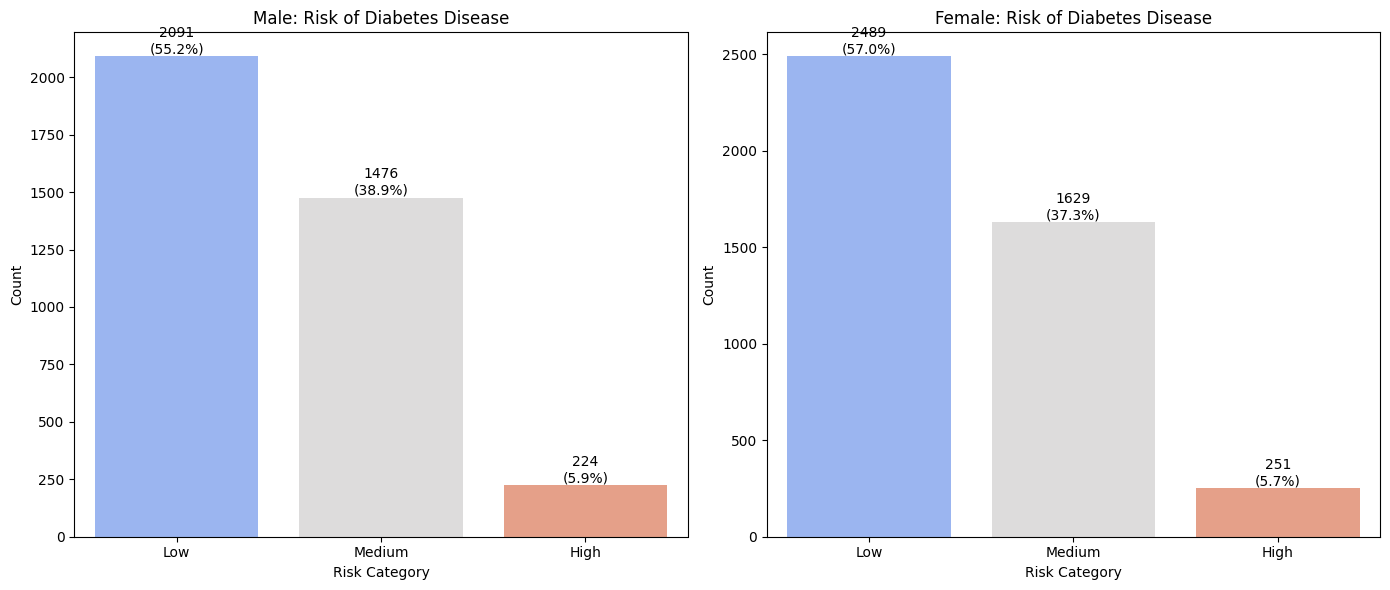

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Separate data for male and female
male_data = df_ncd[df_ncd['sex'] == 'Male']
female_data = df_ncd[df_ncd['sex'] == 'Female']

# Calculate counts and percentages for each category
male_counts = male_data['Risk of Diabetes'].value_counts()
male_percentages = male_data['Risk of Diabetes'].value_counts(normalize=True) * 100

female_counts = female_data['Risk of Diabetes'].value_counts()
female_percentages = female_data['Risk of Diabetes'].value_counts(normalize=True) * 100

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Male Risk of Diabetes (Counts and Percentages)
sns.barplot(x=male_counts.index, y=male_counts.values, ax=axes[0], palette='coolwarm')
axes[0].set_title('Male: Risk of Diabetes Disease')
axes[0].set_xlabel('Risk Category')
axes[0].set_ylabel('Count')

# Adding count and percentage labels for males
for i, count in enumerate(male_counts):
    axes[0].text(i, count + 1, f'{count}\n({male_percentages[i]:.1f}%)',
                 ha='center', va='bottom', color='black', fontsize=10)

# Female Risk of Diabetes (Counts and Percentages)
sns.barplot(x=female_counts.index, y=female_counts.values, ax=axes[1], palette='coolwarm')
axes[1].set_title('Female: Risk of Diabetes Disease')
axes[1].set_xlabel('Risk Category')
axes[1].set_ylabel('Count')

# Adding count and percentage labels for females
for i, count in enumerate(female_counts):
    axes[1].text(i, count + 1, f'{count}\n({female_percentages[i]:.1f}%)',
                 ha='center', va='bottom', color='black', fontsize=10)

plt.tight_layout()
plt.show()


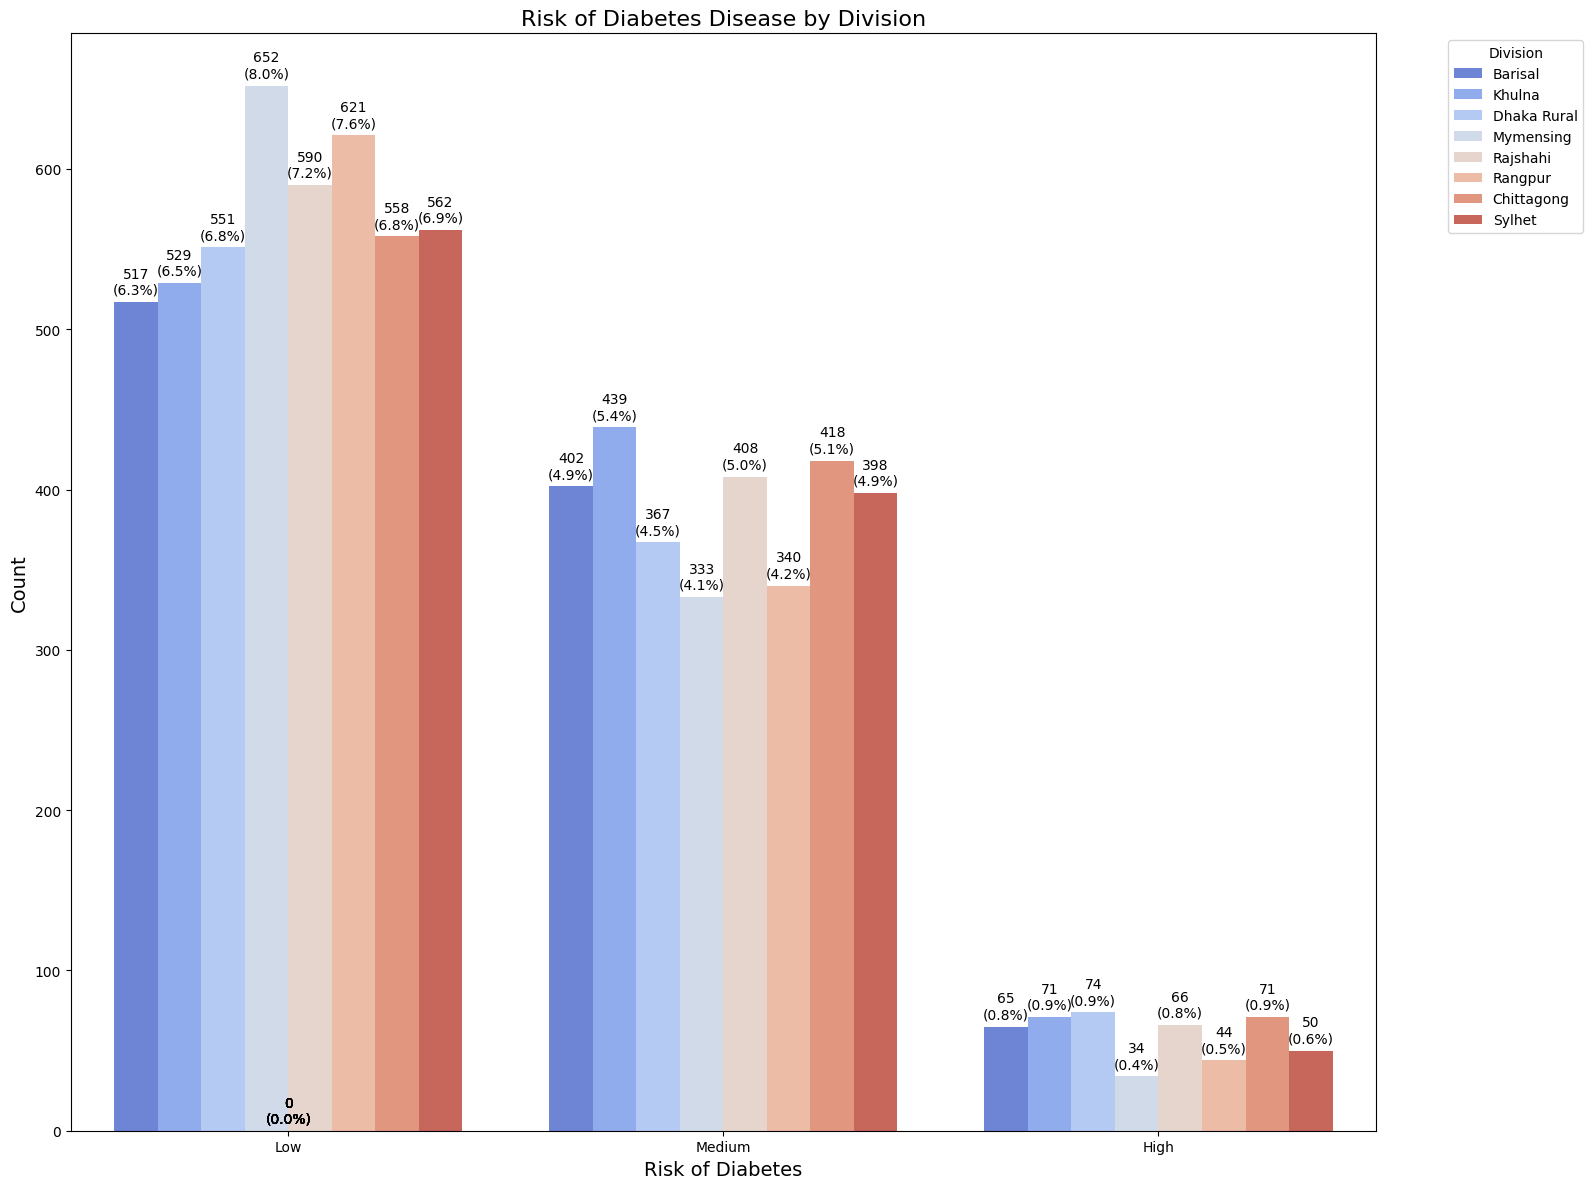

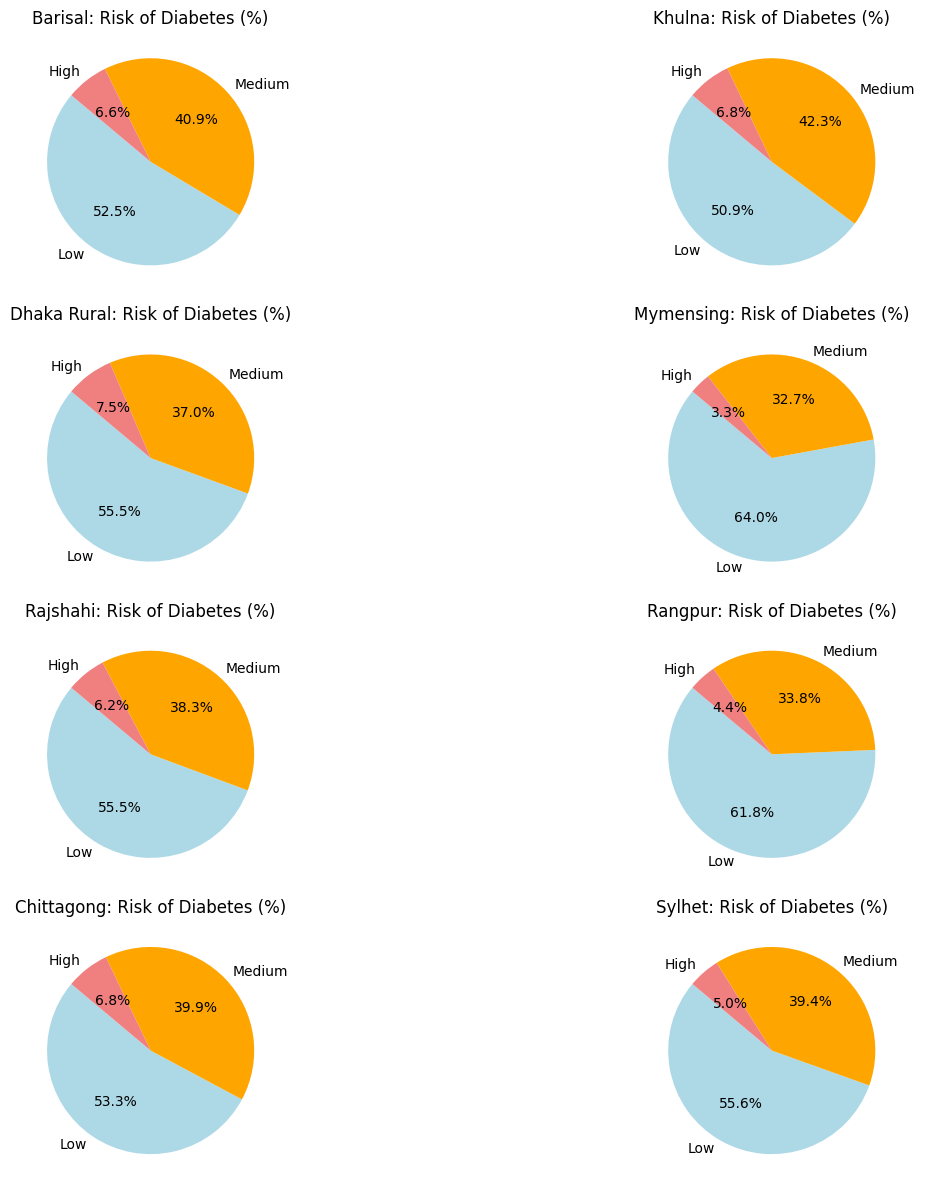

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Overall count plot with both counts and percentages for each risk level across divisions
plt.figure(figsize=(16, 12))
sns.countplot(x='Risk of Diabetes', hue='division', data=df_ncd, palette='coolwarm')
plt.title('Risk of Diabetes Disease by Division', fontsize=16)
plt.xlabel('Risk of Diabetes', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(title='Division', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add count and percentage annotations on top of each bar
total_counts = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total_counts
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()

# Pie charts for each division
divisions = df_ncd['division'].unique()
num_divisions = len(divisions)
plt.figure(figsize=(16, 12))

for idx, division in enumerate(divisions, 1):
    division_data = df_ncd[df_ncd['division'] == division]
    division_counts = division_data['Risk of Diabetes'].value_counts()

    plt.subplot((num_divisions + 1) // 2, 2, idx)  # Arrange pie charts in a grid
    plt.pie(division_counts, labels=division_counts.index, autopct='%1.1f%%',
            colors=['lightblue', 'orange', 'lightcoral'], startangle=140)
    plt.title(f'{division}: Risk of Diabetes (%)')

plt.tight_layout()
plt.show()


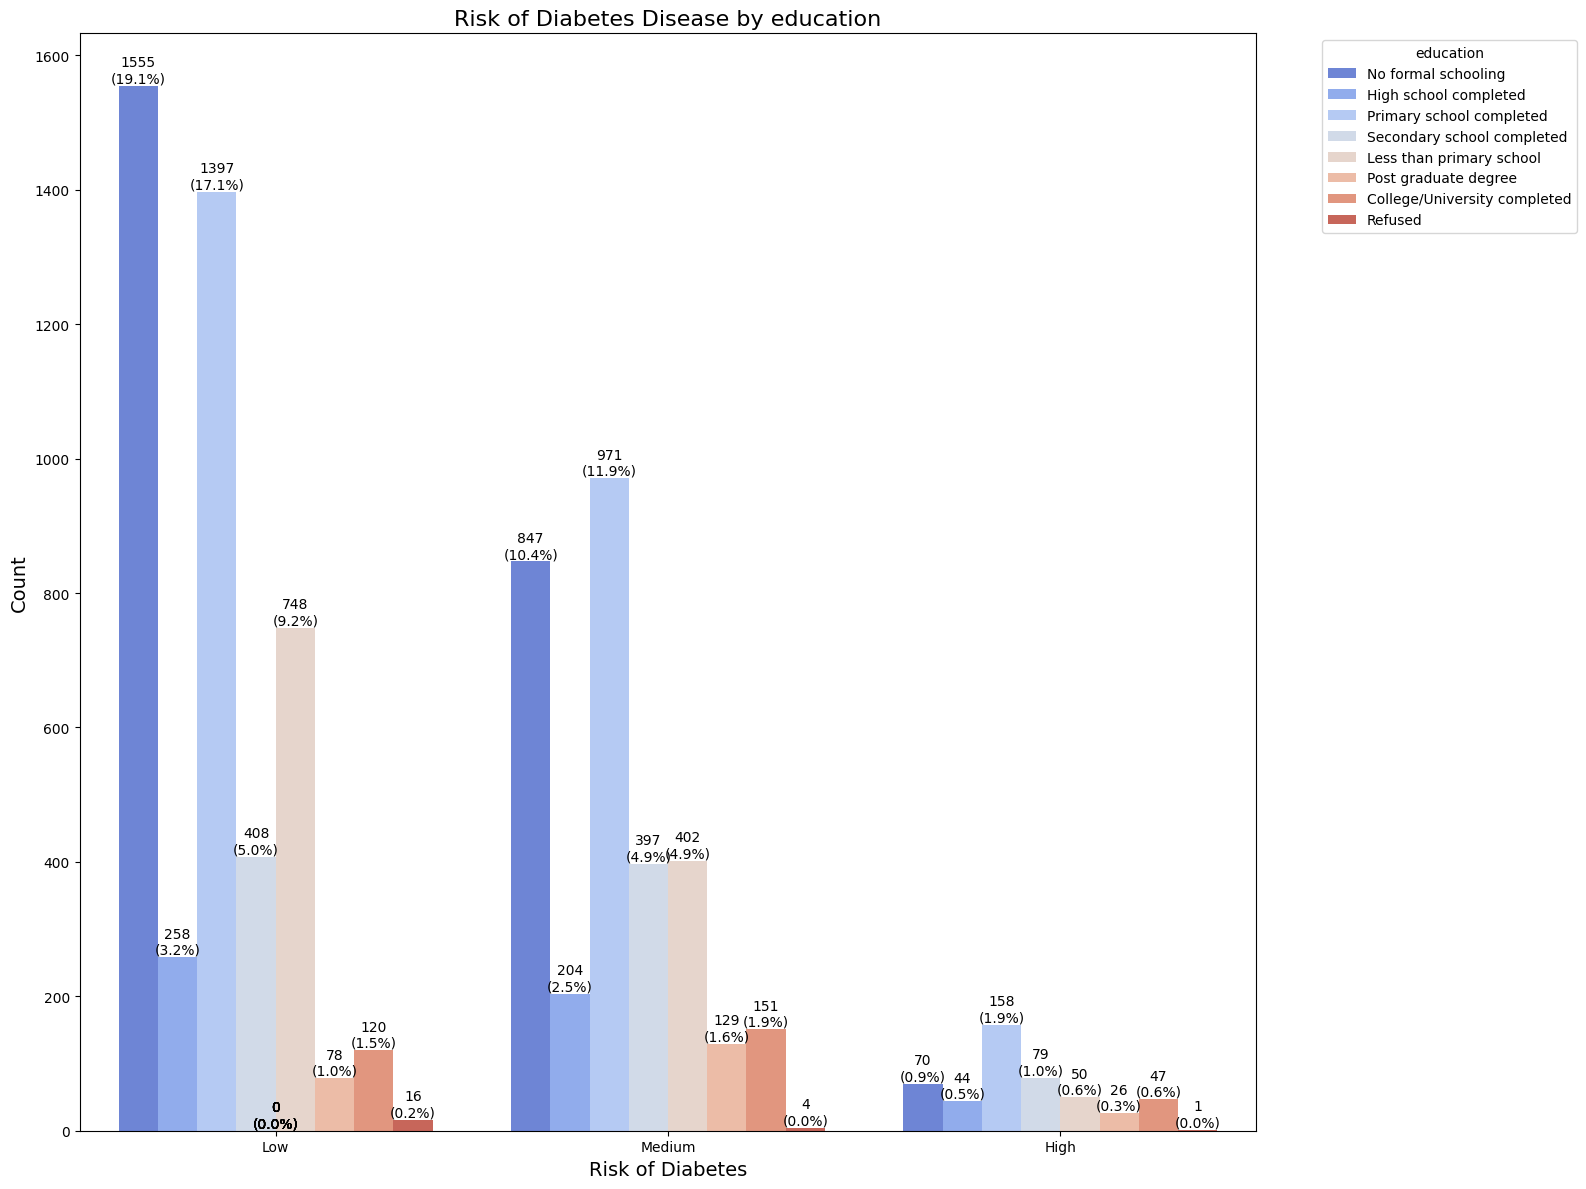

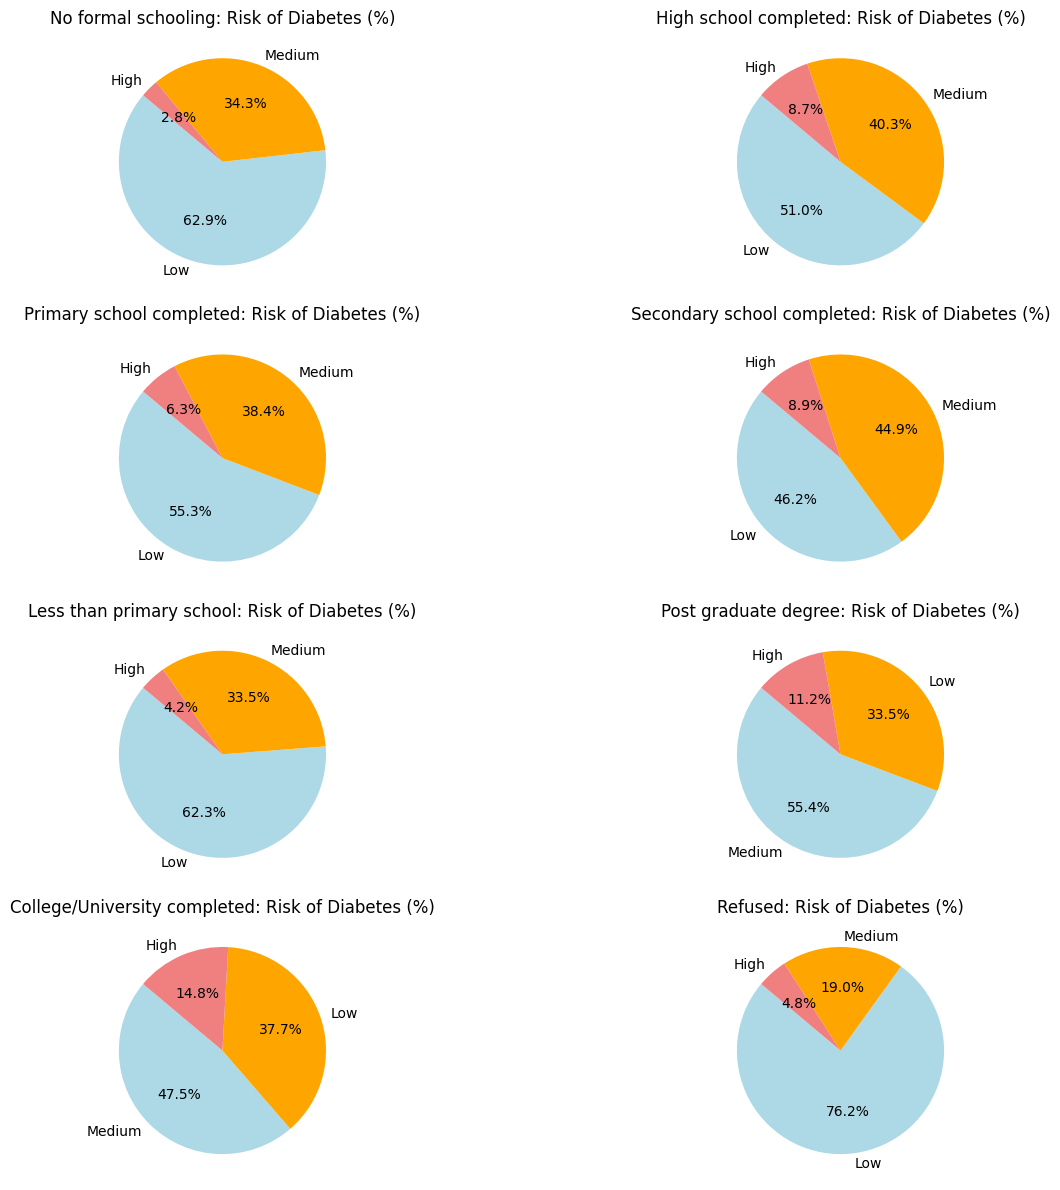

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Overall count plot with both counts and percentages for each risk level across educations
plt.figure(figsize=(16, 12))
sns.countplot(x='Risk of Diabetes', hue='education', data=df_ncd, palette='coolwarm')
plt.title('Risk of Diabetes Disease by education', fontsize=16)
plt.xlabel('Risk of Diabetes', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(title='education', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add count and percentage annotations on top of each bar
total_counts = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total_counts
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()

# Pie charts for each education
educations = df_ncd['education'].unique()
num_educations = len(educations)
plt.figure(figsize=(16, 12))

for idx, education in enumerate(educations, 1):
    education_data = df_ncd[df_ncd['education'] == education]
    education_counts = education_data['Risk of Diabetes'].value_counts()

    plt.subplot((num_educations + 1) // 2, 2, idx)  # Arrange pie charts in a grid
    plt.pie(education_counts, labels=education_counts.index, autopct='%1.1f%%',
            colors=['lightblue', 'orange', 'lightcoral'], startangle=140)
    plt.title(f'{education}: Risk of Diabetes (%)')

plt.tight_layout()
plt.show()


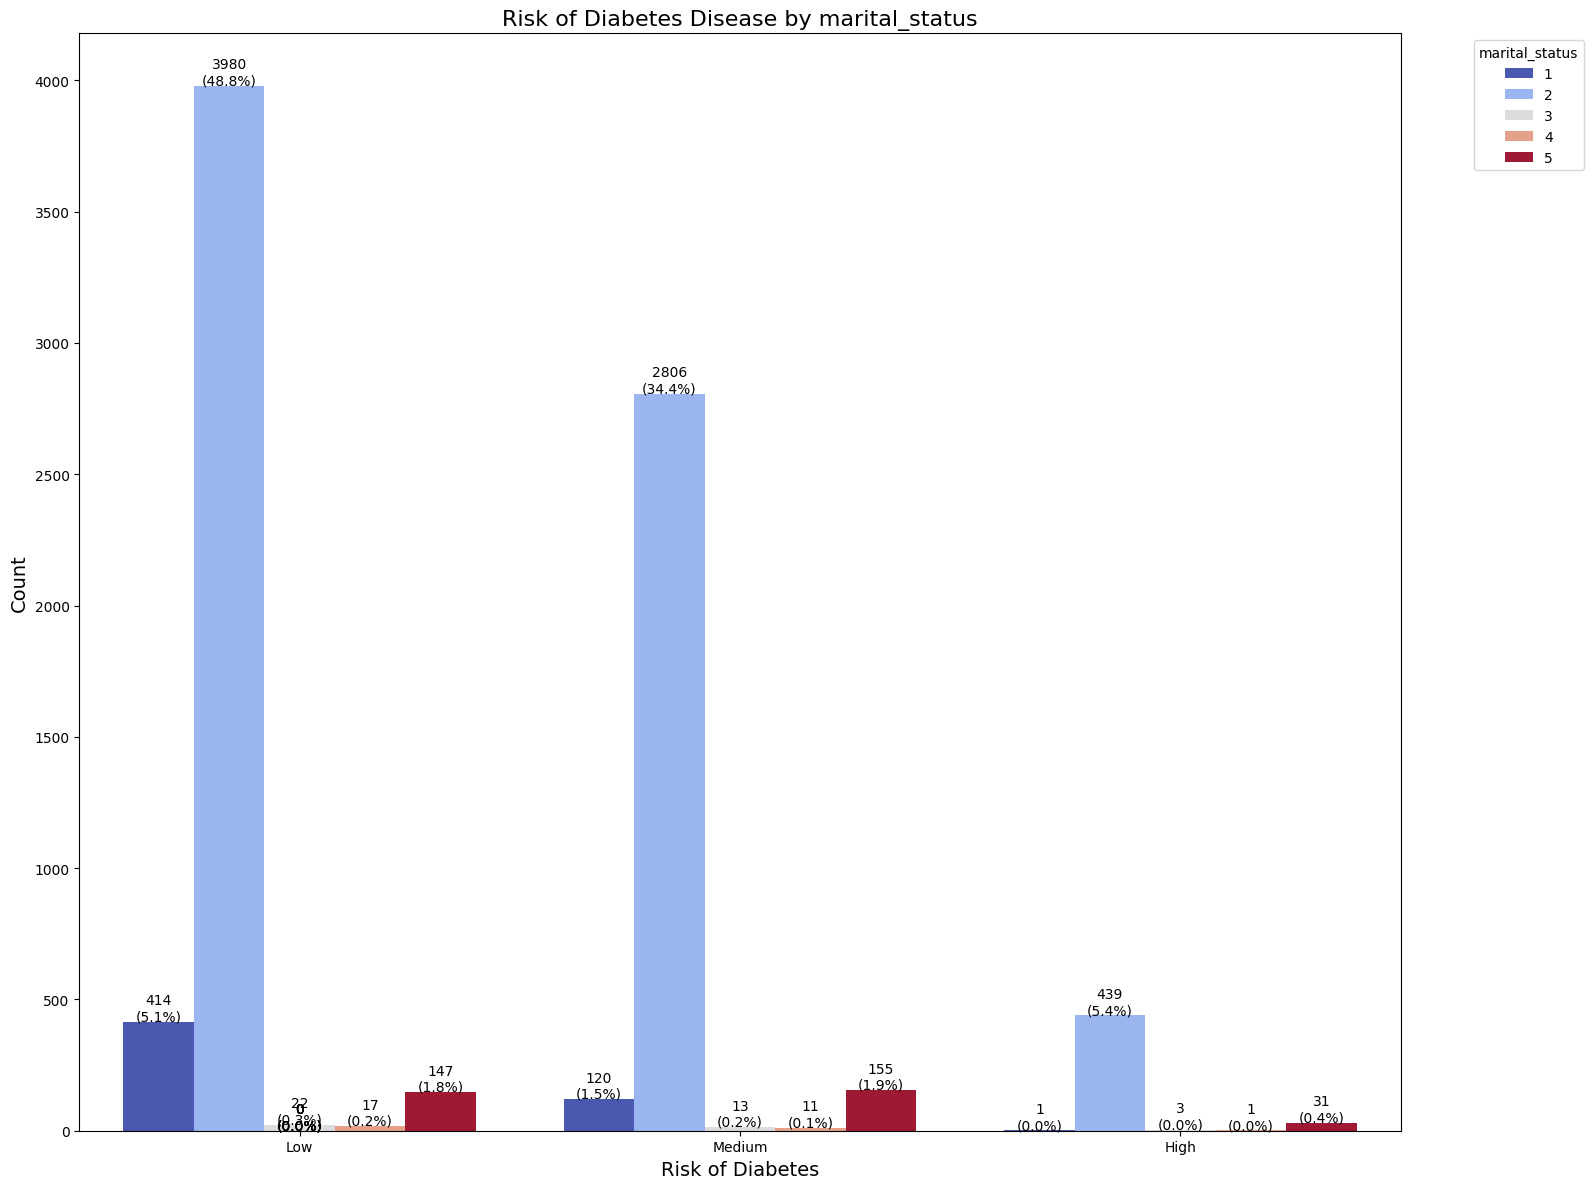

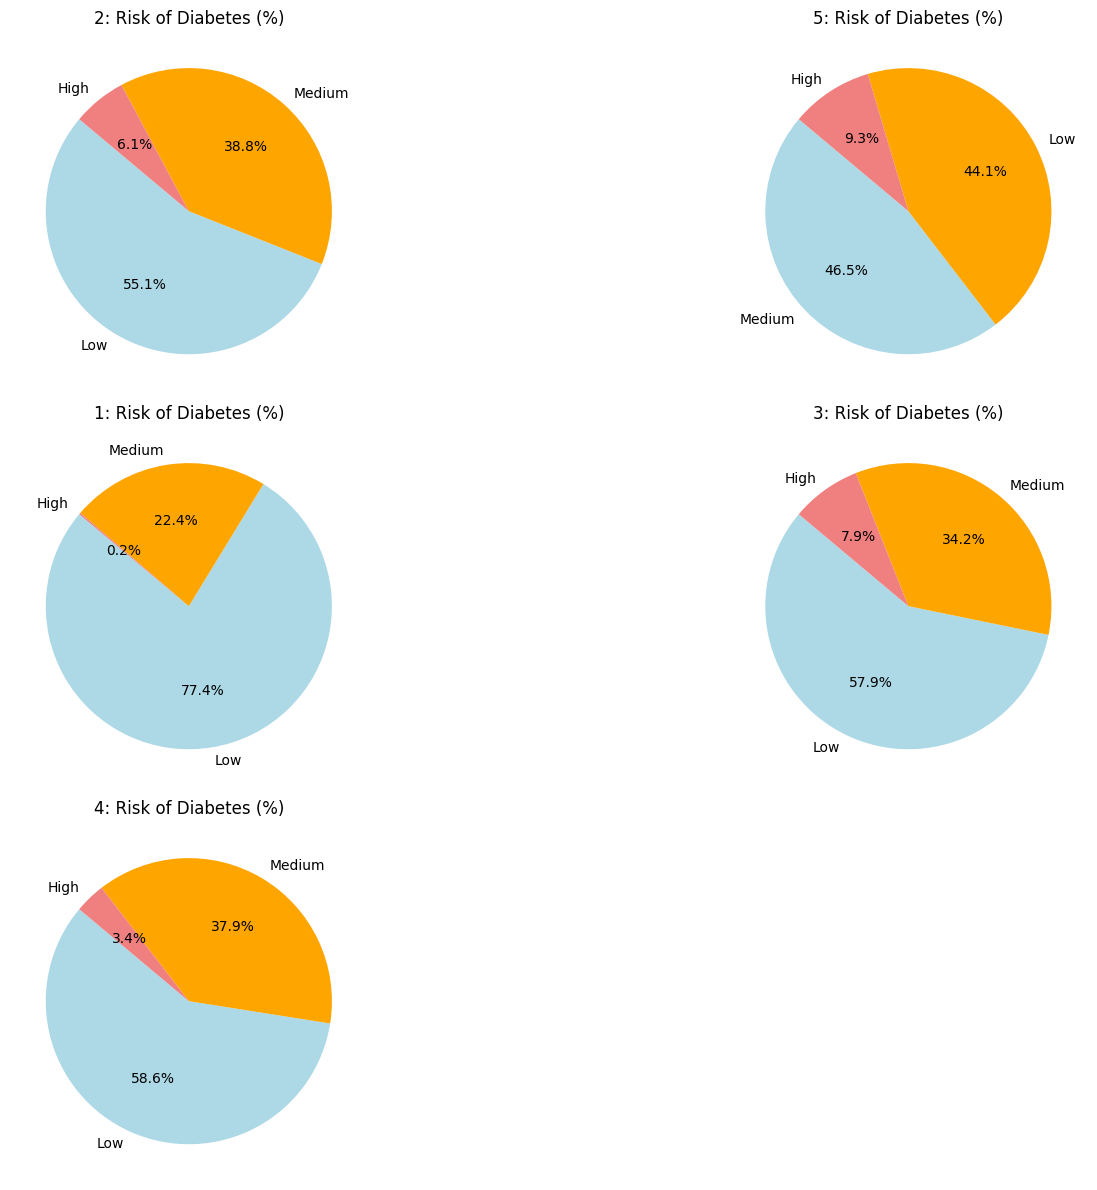

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Overall count plot with both counts and percentages for each risk level across marital_statuss
plt.figure(figsize=(16, 12))
sns.countplot(x='Risk of Diabetes', hue='marital_status', data=df_ncd, palette='coolwarm')
plt.title('Risk of Diabetes Disease by marital_status', fontsize=16)
plt.xlabel('Risk of Diabetes', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(title='marital_status', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add count and percentage annotations on top of each bar
total_counts = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total_counts
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()

# Pie charts for each marital_status
marital_statuss = df_ncd['marital_status'].unique()
num_marital_statuss = len(marital_statuss)
plt.figure(figsize=(16, 12))

for idx, marital_status in enumerate(marital_statuss, 1):
    marital_status_data = df_ncd[df_ncd['marital_status'] == marital_status]
    marital_status_counts = marital_status_data['Risk of Diabetes'].value_counts()

    plt.subplot((num_marital_statuss + 1) // 2, 2, idx)  # Arrange pie charts in a grid
    plt.pie(marital_status_counts, labels=marital_status_counts.index, autopct='%1.1f%%',
            colors=['lightblue', 'orange', 'lightcoral'], startangle=140)
    plt.title(f'{marital_status}: Risk of Diabetes (%)')

plt.tight_layout()
plt.show()


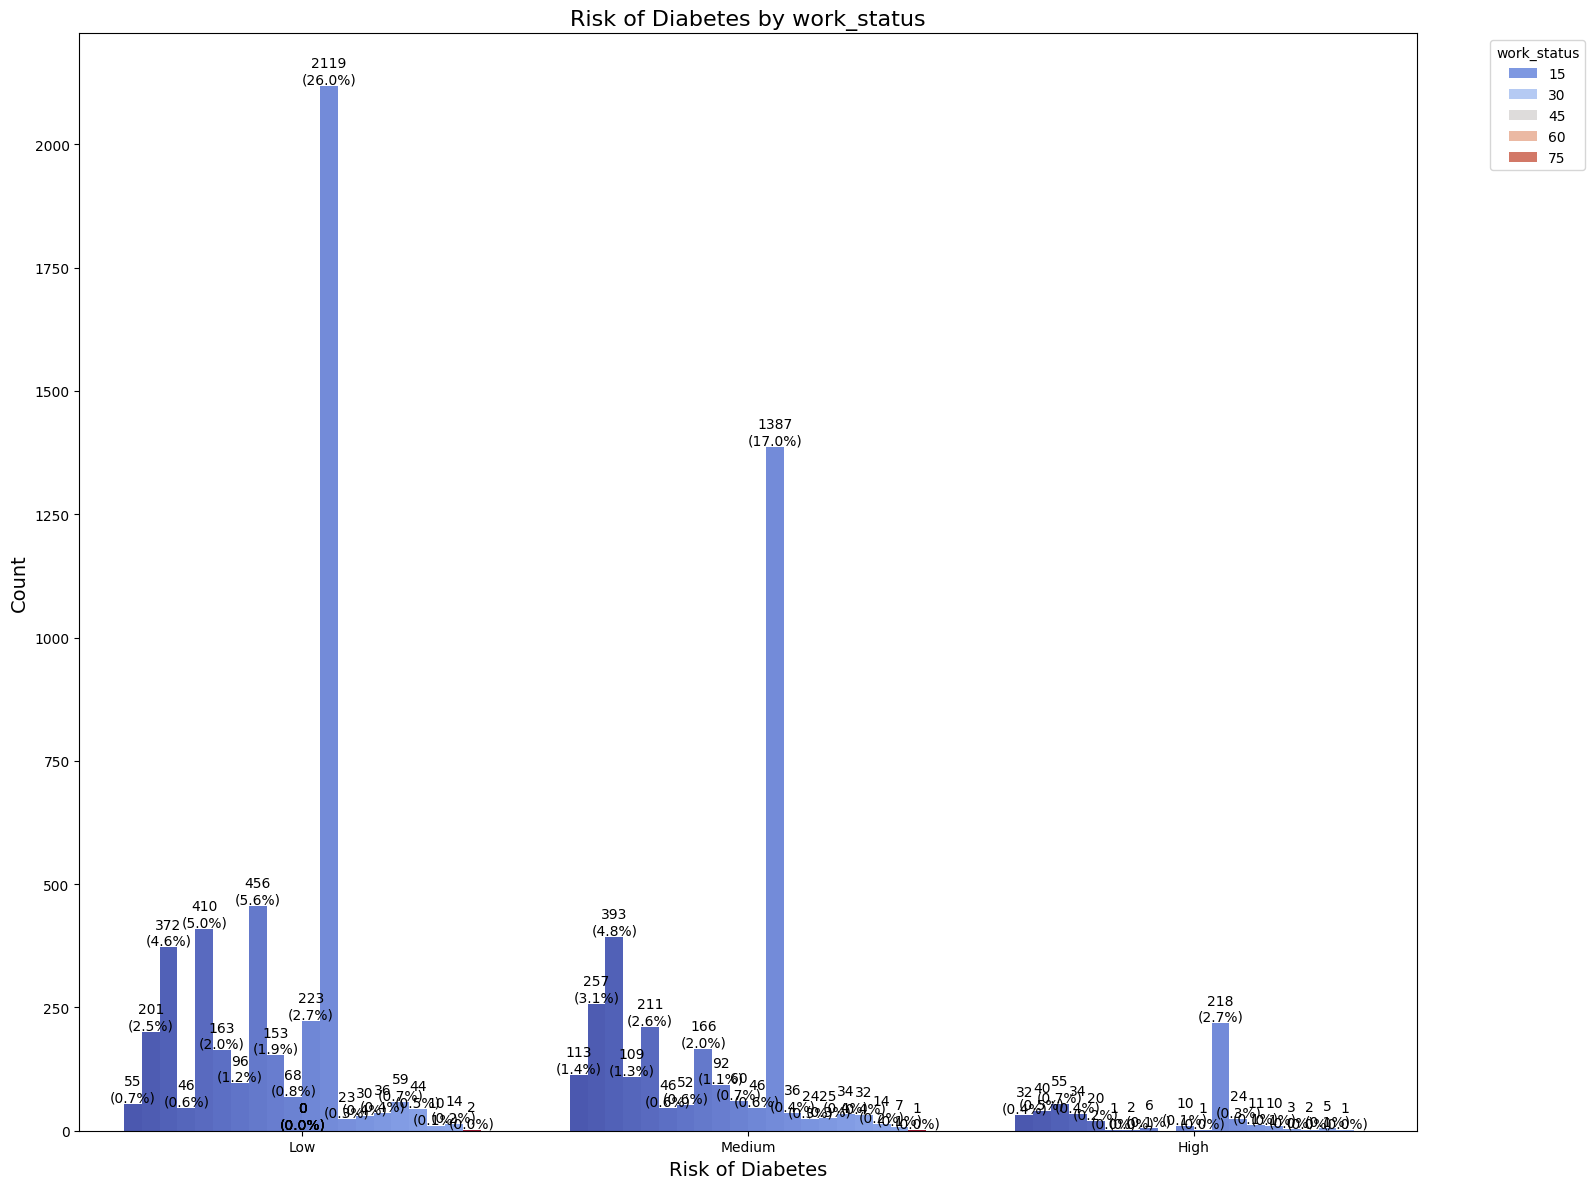

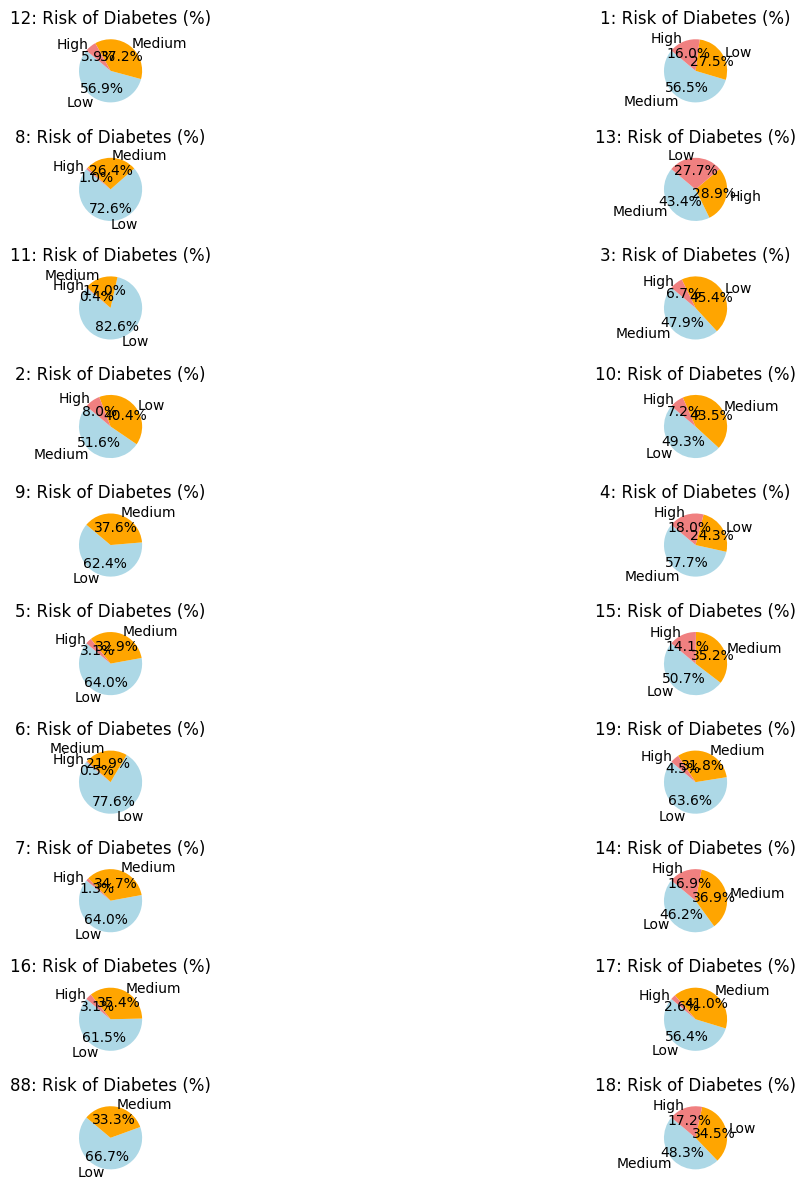

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Overall count plot with both counts and percentages for each risk level across work_statuss
plt.figure(figsize=(16, 12))
sns.countplot(x='Risk of Diabetes', hue='work_status', data=df_ncd, palette='coolwarm')
plt.title('Risk of Diabetes by work_status', fontsize=16)
plt.xlabel('Risk of Diabetes', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(title='work_status', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add count and percentage annotations on top of each bar
total_counts = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total_counts
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()

# Pie charts for each work_status
work_statuss = df_ncd['work_status'].unique()
num_work_statuss = len(work_statuss)
plt.figure(figsize=(16, 12))

for idx, work_status in enumerate(work_statuss, 1):
    work_status_data = df_ncd[df_ncd['work_status'] == work_status]
    work_status_counts = work_status_data['Risk of Diabetes'].value_counts()

    plt.subplot((num_work_statuss + 1) // 2, 2, idx)  # Arrange pie charts in a grid
    plt.pie(work_status_counts, labels=work_status_counts.index, autopct='%1.1f%%',
            colors=['lightblue', 'orange', 'lightcoral'], startangle=140)
    plt.title(f'{work_status}: Risk of Diabetes (%)')

plt.tight_layout()
plt.show()


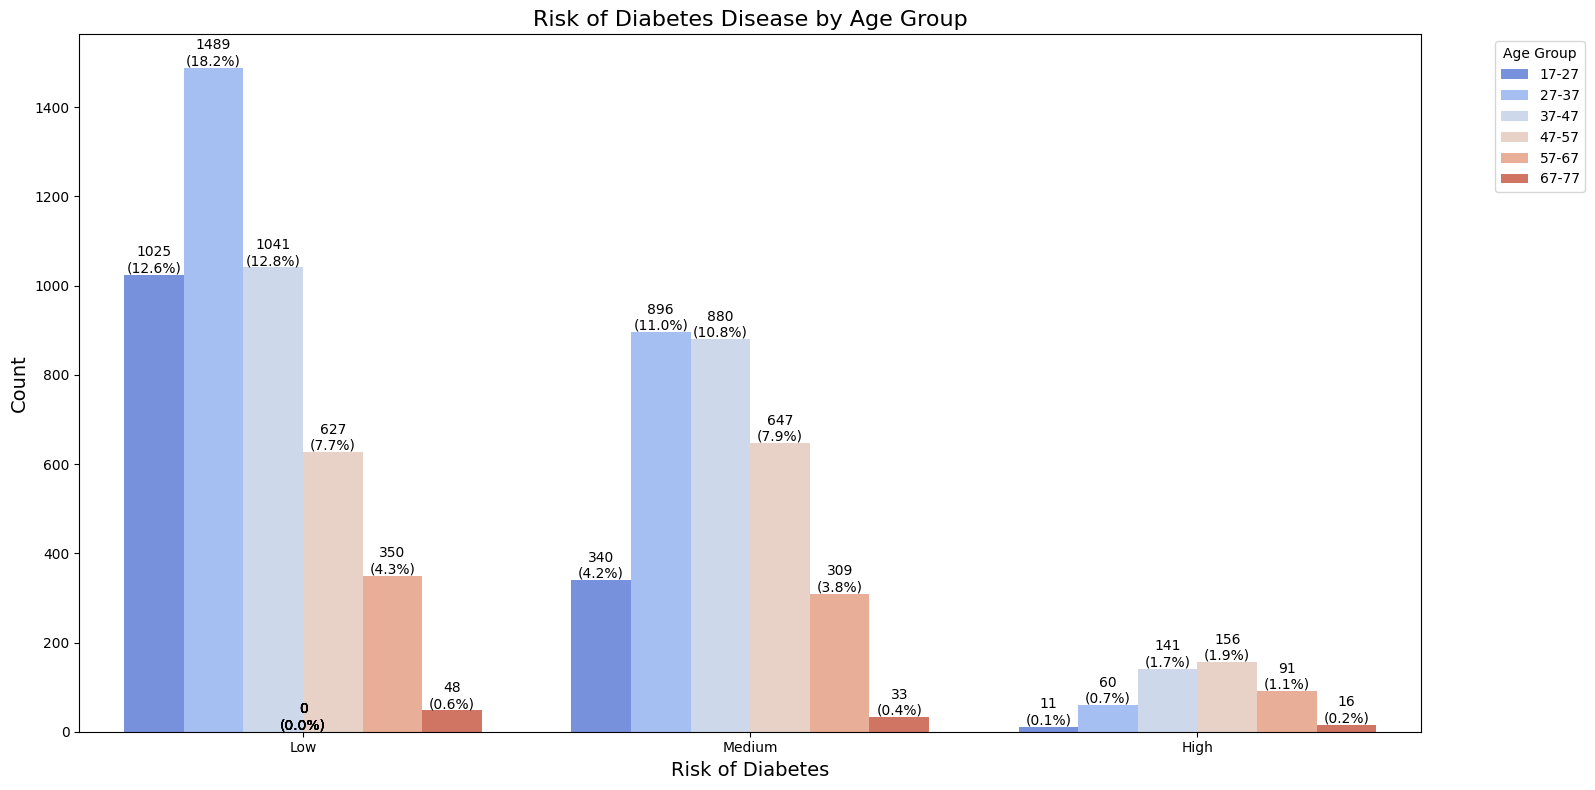

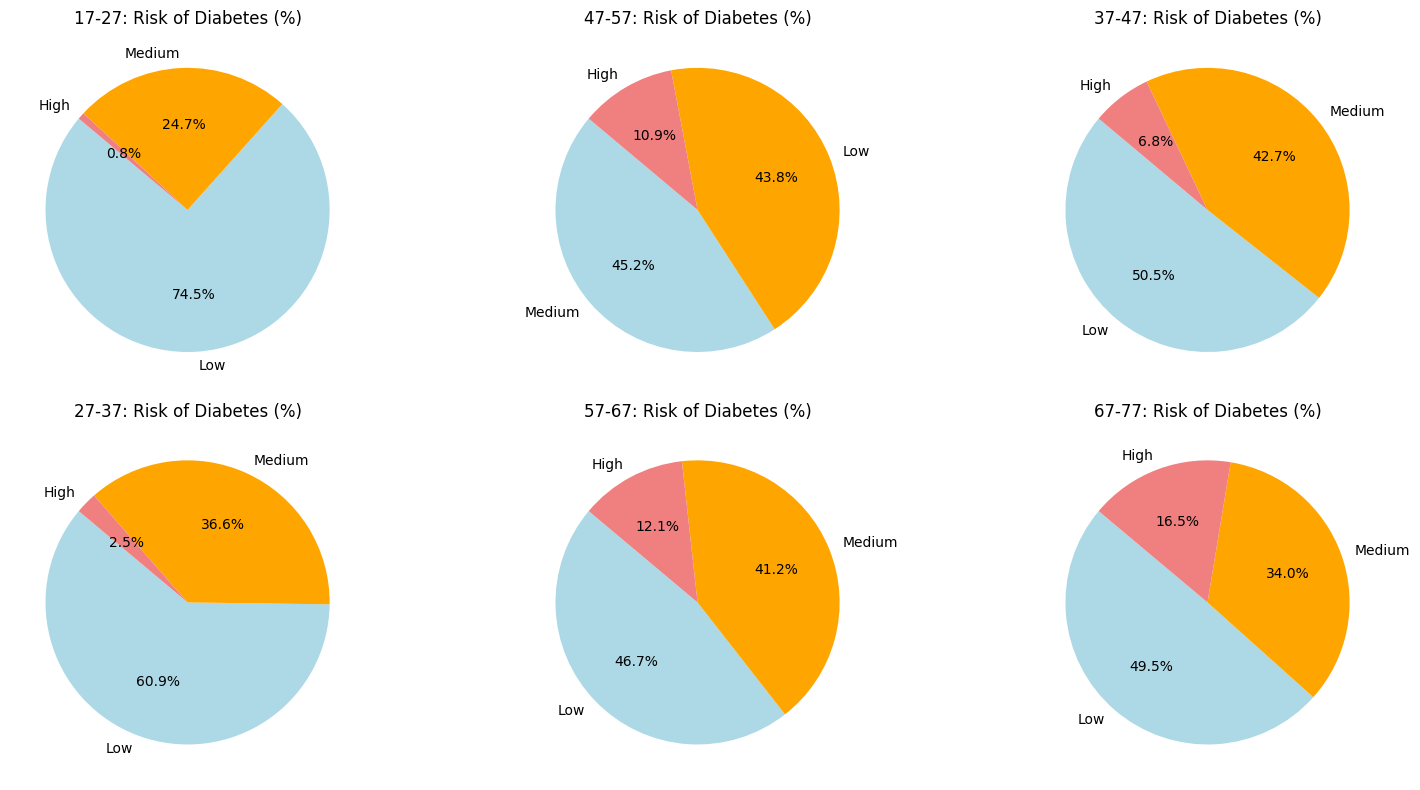

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Create age groups
age_bins = [17, 27, 37, 47, 57, 67, 77]  # Age bin boundaries
age_labels = ['17-27', '27-37', '37-47', '47-57', '57-67', '67-77']  # Age group labels

# Add the age group column to the dataset
df_ncd['age_group'] = pd.cut(df_ncd['age'], bins=age_bins, labels=age_labels, right=False)

# Overall count plot with counts and percentages
plt.figure(figsize=(16, 8))
sns.countplot(x='Risk of Diabetes', hue='age_group', data=df_ncd, palette='coolwarm')
plt.title('Risk of Diabetes Disease by Age Group', fontsize=16)
plt.xlabel('Risk of Diabetes', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(title='Age Group', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add count and percentage annotations
total_counts = len(df_ncd)
for p in plt.gca().patches:
    height = p.get_height()
    count = int(height)
    percentage = 100 * count / total_counts
    plt.text(p.get_x() + p.get_width() / 2, height + 5,
             f'{count}\n({percentage:.1f}%)', ha="center", fontsize=10, color="black")

plt.tight_layout()
plt.show()

# Pie charts for each age group
age_groups = df_ncd['age_group'].unique()
num_age_groups = len(age_groups)
plt.figure(figsize=(16, 8))

for idx, age_group in enumerate(age_groups, 1):
    age_group_data = df_ncd[df_ncd['age_group'] == age_group]
    age_group_counts = age_group_data['Risk of Diabetes'].value_counts()

    plt.subplot((num_age_groups + 2) // 3, 3, idx)  # Arrange pie charts in a grid
    plt.pie(age_group_counts, labels=age_group_counts.index, autopct='%1.1f%%',
            colors=['lightblue', 'orange', 'lightcoral'], startangle=140)
    plt.title(f'{age_group}: Risk of Diabetes (%)')

plt.tight_layout()
plt.show()


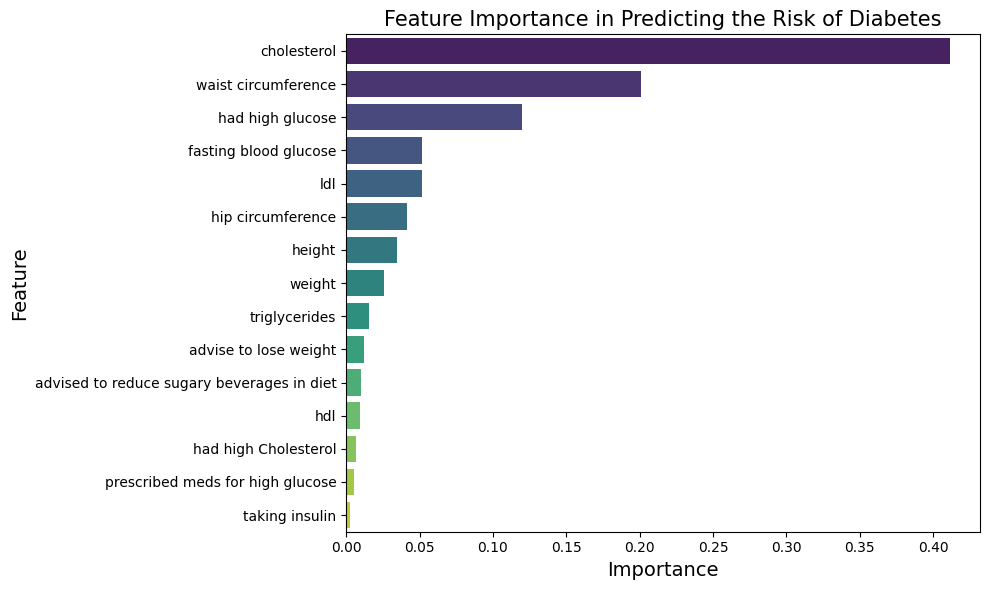

Feature Importance (sorted):
                                       Feature  Importance
11                                 cholesterol       0.411
9                          waist circumference       0.201
1                             had high glucose       0.120
12                       fasting blood glucose       0.052
14                                         ldl       0.052
10                           hip circumference       0.042
7                                       height       0.035
8                                       weight       0.026
6                                triglycerides       0.016
4                        advise to lose weight       0.012
5   advised to reduce sugary beverages in diet       0.010
13                                         hdl       0.009
0                         had high Cholesterol       0.007
2             prescribed meds for high glucose       0.005
3                               taking insulin       0.002


In [ ]:
# Import necessary libraries
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load your dataset (replace with the actual path to your file)
# df_ncd = pd.read_csv('path_to_your_data.csv')  # Replace with the correct path

# Example: Define features and target (make sure these match your dataset columns)
features = ['had high Cholesterol', 'had high glucose', 'prescribed meds for high glucose',
    'taking insulin', 'advise to lose weight', 'advised to reduce sugary beverages in diet',
    'triglycerides', 'height', 'weight', 'waist circumference', 'hip circumference',
    'cholesterol', 'fasting blood glucose', 'hdl', 'ldl']

# Separate features (X) and target variable (y)
X = df_ncd[features]  # Select features
y = df_ncd['Risk of Diabetes']  # Assuming 'Risk of Diabetes' is your target column

# Split the data into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Train a decision tree classifier
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)

# Get feature importances
importances = clf.feature_importances_

# Create a DataFrame to view feature importance
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
})

# Sort the features by importance
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title('Feature Importance in Predicting the Risk of Diabetes', fontsize=15)
plt.xlabel('Importance', fontsize=14)
plt.ylabel('Feature', fontsize=14)
plt.tight_layout()
plt.show()

# Print the sorted importance values
print("Feature Importance (sorted):")
print(importance_df)


In [ ]:
from sklearn.model_selection import train_test_split

# Define X (features) and y (target)
X = df_ncd[features]  # Features from clustering
y = df_ncd['Risk of Diabetes']  # Target variable

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report

# Dictionary to store models and their names
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Support Vector Machine': SVC(random_state=42)
}

# Dictionary to hold evaluation results
results = {}

# Train and evaluate each model
for name, model in models.items():
    model.fit(X_train, y_train)  # Train model
    y_pred = model.predict(X_test)  # Make predictions on test set

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')

    # Store results
    results[name] = {
        'Accuracy': accuracy,
        'F1 Score': f1,
        'Precision': precision,
        'Recall': recall
    }
    # Print classification report for each model
    print(f"Classification Report for {name}:\n", classification_report(y_test, y_pred))


Classification Report for Logistic Regression:
               precision    recall  f1-score   support

        High       0.98      0.94      0.96        87
         Low       0.94      0.95      0.95       932
      Medium       0.92      0.91      0.91       613

    accuracy                           0.94      1632
   macro avg       0.95      0.93      0.94      1632
weighted avg       0.94      0.94      0.93      1632

Classification Report for K-Nearest Neighbors:
               precision    recall  f1-score   support

        High       0.48      0.30      0.37        87
         Low       0.90      0.94      0.92       932
      Medium       0.84      0.83      0.84       613

    accuracy                           0.87      1632
   macro avg       0.74      0.69      0.71      1632
weighted avg       0.86      0.87      0.86      1632

Classification Report for Decision Tree:
               precision    recall  f1-score   support

        High       0.90      0.80      0.85  

In [ ]:
import pandas as pd

# Convert results to DataFrame
results_df = pd.DataFrame(results).T  # Transpose for easier viewing
print(results_df)


                        Accuracy  F1 Score  Precision  Recall
Logistic Regression        0.935     0.935      0.935   0.935
K-Nearest Neighbors        0.866     0.861      0.858   0.866
Decision Tree              0.906     0.906      0.906   0.906
Random Forest              0.939     0.939      0.939   0.939
Support Vector Machine     0.882     0.874      0.874   0.882


In [ ]:
#Smote

In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import LabelEncoder

# Encode the 'Risk of Diabetes' categories to integers
le = LabelEncoder()
df_ncd['Risk of Diabetes Encoded'] = le.fit_transform(df_ncd['Risk of Diabetes'])

# Separate features and target
X = df_ncd[selected_features]
y = df_ncd['Risk of Diabetes Encoded']

# Apply SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Decode the target back to the original categories
y_resampled_decoded = le.inverse_transform(y_resampled)

# Create a new DataFrame with the resampled data
df_resampled = pd.DataFrame(X_resampled, columns=selected_features)
df_resampled['Risk of Diabetes'] = y_resampled_decoded

# Check the distribution of the target variable after SMOTE
print("Distribution of 'Risk of Diabetes' after SMOTE:")
print(df_resampled['Risk of Diabetes'].value_counts())



Distribution of 'Risk of Diabetes' after SMOTE:
Risk of Diabetes
Low       4580
Medium    4580
High      4580
Name: count, dtype: int64


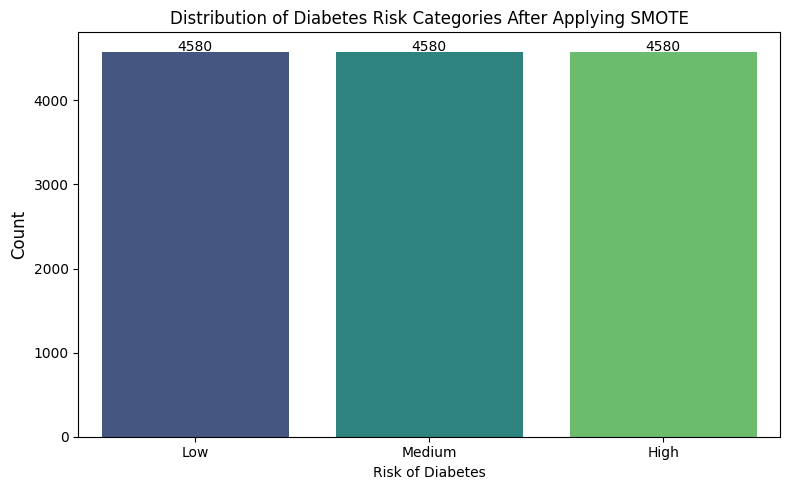

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the occurrences of each risk category after SMOTE
risk_counts = df_resampled['Risk of Diabetes'].value_counts()

# Plot the bar graph
plt.figure(figsize=(8, 5))
sns.barplot(x=risk_counts.index, y=risk_counts.values, palette='viridis')

# Add titles and labels
plt.title('Distribution of Diabetes Risk Categories After Applying SMOTE', fontsize=12)
plt.ylabel('Count', fontsize=12)

# Show values on top of the bars
for i, value in enumerate(risk_counts.values):
    plt.text(i, value + 5, str(value), ha='center', fontsize=10)

# Display the plot
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Prepare the data
X = df_resampled[selected_features]
y = df_resampled['Risk of Diabetes']

# Encode the target variable (if not already encoded)
y_encoded = le.fit_transform(y)  # Using the same LabelEncoder as before

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

# Initialize models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100),
    'Support Vector Machine': SVC(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5)
}

# Initialize dictionary to store results
results = {}

# Train and evaluate each model
for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Get classification metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)

    # Extract Precision, Recall, F1-Score for each model class
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']

    # Store results in the dictionary
    results[model_name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1_score,
        'Confusion Matrix': confusion_matrix(y_test, y_pred)
    }

# Convert results dictionary to DataFrame
results_df = pd.DataFrame(results).T  # Transpose for easier viewing

# Print results
print(results_df)


                       Accuracy Precision Recall F1-Score  \
Logistic Regression       0.972     0.972  0.972    0.972   
Random Forest             0.983     0.983  0.983    0.983   
Support Vector Machine    0.780     0.793  0.780    0.777   
Decision Tree             0.969     0.969  0.969    0.969   
K-Nearest Neighbors       0.900     0.901  0.900    0.899   

                                                       Confusion Matrix  
Logistic Regression           [[916, 0, 0], [2, 879, 35], [3, 38, 875]]  
Random Forest                 [[916, 0, 0], [6, 890, 20], [4, 16, 896]]  
Support Vector Machine  [[569, 107, 240], [21, 810, 85], [59, 93, 764]]  
Decision Tree                 [[908, 1, 7], [7, 881, 28], [9, 34, 873]]  
K-Nearest Neighbors        [[898, 7, 11], [46, 799, 71], [80, 61, 775]]  


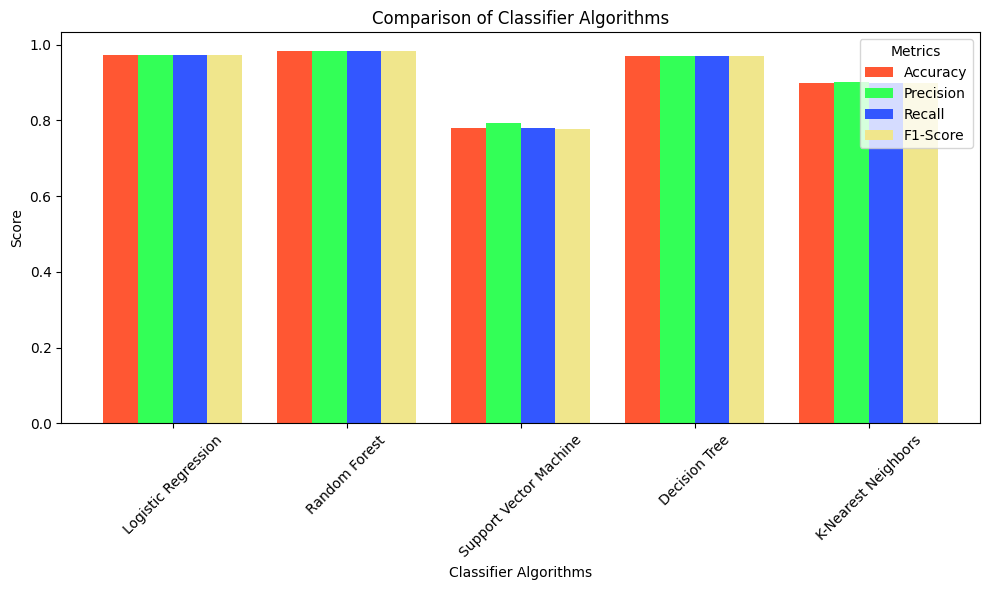

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Prepare the data
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

# Create a DataFrame from the results for easier plotting
metrics_df = results_df[metrics]

# Define colors for each metric
colors = ['#FF5733', '#33FF57', '#3357FF', '#F0E68C']

# Plot the comparison of classifiers using bar graphs with different colors for each metric
plt.figure(figsize=(10, 6))

# Loop through each metric and plot its bars with different colors
bar_width = 0.2  # Set the width of the bars
index = np.arange(len(metrics_df))  # Position for each classifier

for i, metric in enumerate(metrics):
    plt.bar(index + i * bar_width, metrics_df[metric], bar_width, label=metric, color=colors[i])

# Add labels and title
plt.xlabel('Classifier Algorithms')
plt.ylabel('Score')
plt.title('Comparison of Classifier Algorithms')

# Adjust x-ticks to be centered and show classifier names
plt.xticks(index + bar_width * 1.5, metrics_df.index, rotation=45)

# Add legend
plt.legend(title='Metrics')

# Tight layout to prevent overlapping labels
plt.tight_layout()

# Show plot
plt.show()


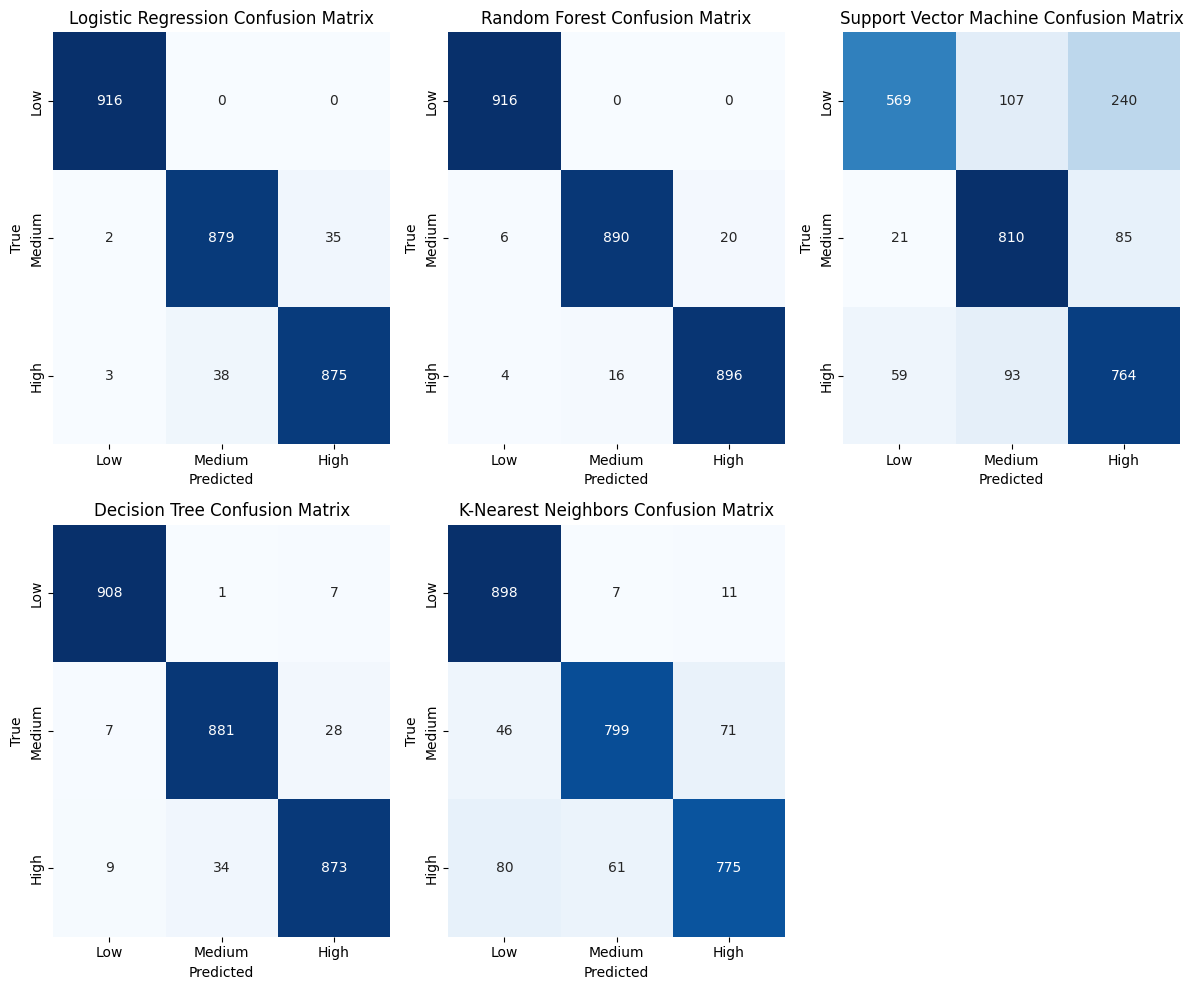

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Plot the confusion matrix for each model
plt.figure(figsize=(12, 10))

# Iterate through models and plot their confusion matrix
for i, (model_name, result) in enumerate(results.items()):
    cm = result['Confusion Matrix']

    plt.subplot(2, 3, i + 1)  # Create subplots (2 rows, 3 columns)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Low', 'Medium', 'High'], yticklabels=['Low', 'Medium', 'High'])
    plt.title(f'{model_name} Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')

plt.tight_layout()
plt.show()


In [ ]:
#GridSearch

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Define models and hyperparameter grids for GridSearchCV
models = {
    'Random Forest': RandomForestClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Support Vector Machine': SVC(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier()
}

param_grids = {
    'Random Forest': {
        'n_estimators': [50, 100, 200],
        'max_depth': [10, 20, 30, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'bootstrap': [True, False]
    },
    'Logistic Regression': {
        'C': [0.1, 1, 10],
        'solver': ['lbfgs', 'liblinear'],
        'penalty': ['l2']
    },
    'Support Vector Machine': {
        'C': [0.1, 1, 10],
        'kernel': ['linear', 'rbf'],
        'gamma': ['scale', 'auto']
    },
    'Decision Tree': {
        'max_depth': [10, 20, 30, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4]
    },
    'K-Nearest Neighbors': {
        'n_neighbors': [3, 5, 7, 10],
        'weights': ['uniform', 'distance'],
        'metric': ['euclidean', 'manhattan']
    }
}

# Hyperparameter tuning with GridSearchCV
best_models_grid = {}

for model_name, model in models.items():
    print(f"Performing GridSearchCV for {model_name}...")

    grid_search = GridSearchCV(estimator=model, param_grid=param_grids[model_name], cv=5, n_jobs=-1, verbose=1)
    grid_search.fit(X_train, y_train)

    best_models_grid[model_name] = grid_search.best_estimator_
    print(f"Best parameters for {model_name}: {grid_search.best_params_}\n")

# Step 2: Evaluate the best models
for model_name, model in best_models_grid.items():
    print(f"Evaluating {model_name} after GridSearchCV...")
    y_pred = model.predict(X_test)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("\n")


Performing GridSearchCV for Random Forest...
Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best parameters for Random Forest: {'bootstrap': False, 'max_depth': 30, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}

Performing GridSearchCV for Logistic Regression...
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best parameters for Logistic Regression: {'C': 10, 'penalty': 'l2', 'solver': 'liblinear'}

Performing GridSearchCV for Support Vector Machine...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters for Support Vector Machine: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}

Performing GridSearchCV for Decision Tree...
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters for Decision Tree: {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2}

Performing GridSearchCV for K-Nearest Neighbors...
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters for

Visualizing Confusion Matrix for Random Forest...


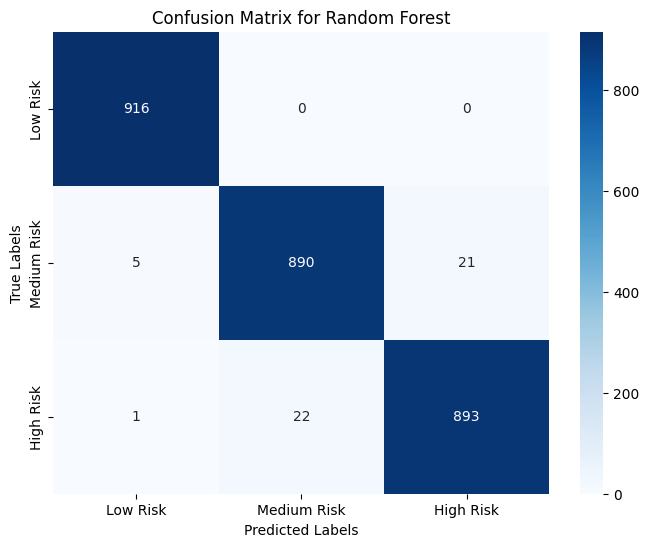

Visualizing Confusion Matrix for Logistic Regression...


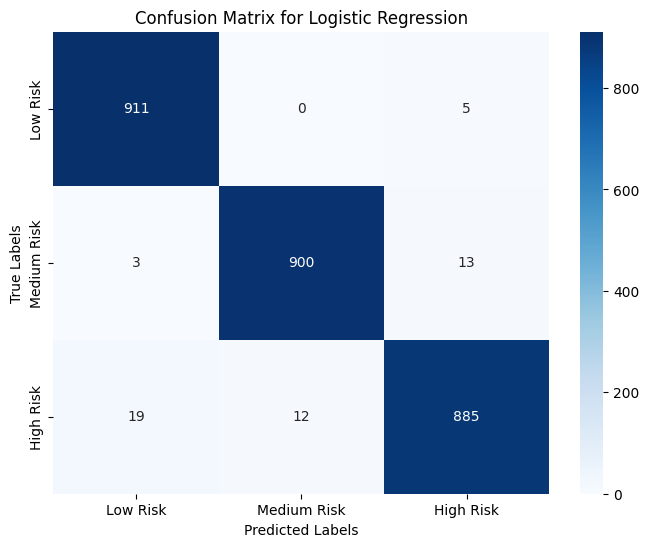

Visualizing Confusion Matrix for Support Vector Machine...


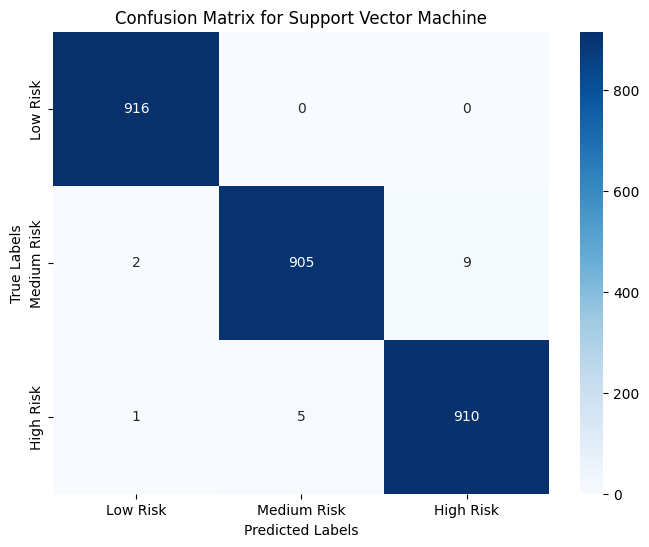

Visualizing Confusion Matrix for Decision Tree...


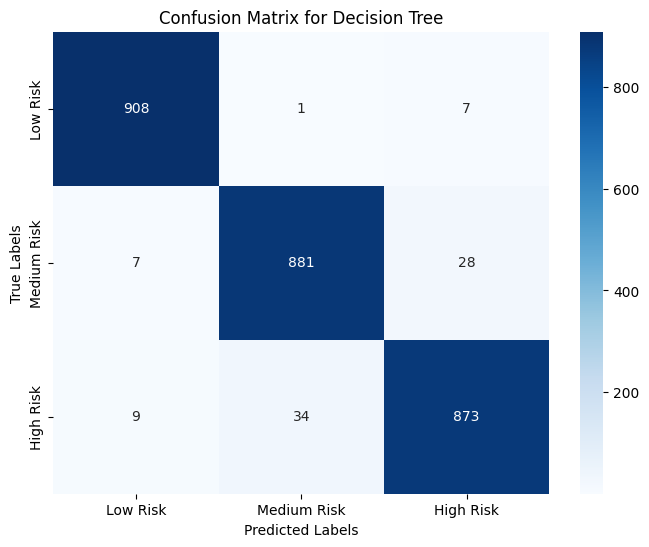

Visualizing Confusion Matrix for K-Nearest Neighbors...


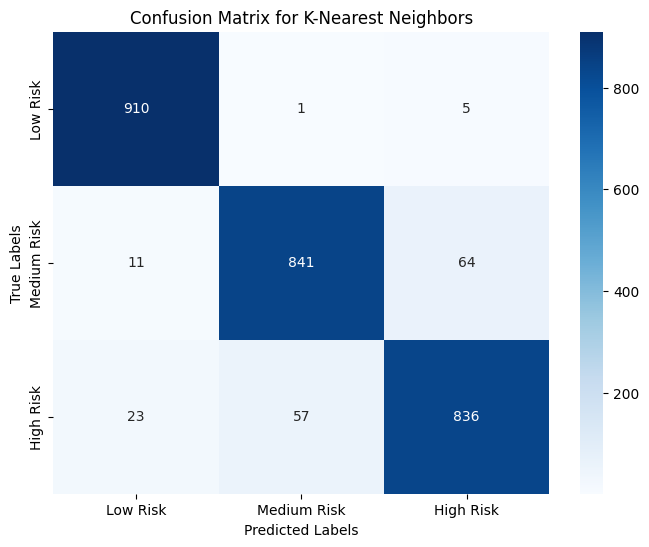

In [ ]:
def visualize_confusion_matrices(best_models, X_test, y_test, class_names):
    import matplotlib.pyplot as plt
    import seaborn as sns
    from sklearn.metrics import confusion_matrix

    def plot_confusion_matrix(cm, model_name, class_names):
        plt.figure(figsize=(8, 6))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
        plt.title(f"Confusion Matrix for {model_name}")
        plt.xlabel("Predicted Labels")
        plt.ylabel("True Labels")
        plt.show()

    for model_name, model in best_models.items():
        print(f"Visualizing Confusion Matrix for {model_name}...")
        y_pred = model.predict(X_test)
        cm = confusion_matrix(y_test, y_pred)
        plot_confusion_matrix(cm, model_name, class_names)

# Call the function with appropriate inputs
visualize_confusion_matrices(best_models_grid, X_test, y_test, ['Low Risk', 'Medium Risk', 'High Risk'])
